<a href="https://colab.research.google.com/github/melinahou/Agent_1/blob/main/pipeline_Agent1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# PART 1-Data Preparation and Shared Components
# ----------------------------------------------------------------------------
# 0. Imports & global config
# ----------------------------------------------------------------------------
import os, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from pathlib import Path
from sklearn import set_config
from sklearn.impute import KNNImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedKFold, GridSearchCV,
    cross_validate, cross_val_predict,
    train_test_split
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    brier_score_loss, average_precision_score, roc_auc_score,
    precision_recall_curve, roc_curve,
    precision_score, recall_score, f1_score,
    confusion_matrix
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

set_config(transform_output="pandas")

RANDOM_STATE = 42

RAW_SENSORS = [
    'Air_temperature_K',
    'Process_temperature_K',
    'Rotational_speed_rpm',
    'Torque_Nm',
    'Tool_wear_min'
]

TYPE_MAP = {
    'L': 0,
    'M': 1,
    'H': 2
}



# ============================================================
# GLOBAL PUBLICATION-GRADE FIGURE STYLE
# ============================================================

FIG_DIR = Path("/content/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Standard dimensions
FIG_SIZE = (6, 4)
FIG_SIZE_WIDE = (12, 5)
FIG_SIZE_TALL = (6, 8)

# Okabe-Ito colorblind-friendly palette
COLORS = {
    "blue": "#0072B2",
    "orange": "#E69F00",
    "green": "#009E73",
    "red": "#D55E00",
    "purple": "#CC79A7",
    "skyblue": "#56B4E9",
    "yellow": "#F0E442",
    "black": "#000000"
}

COLOR_PALETTE = [
    COLORS["blue"],
    COLORS["orange"],
    COLORS["green"],
    COLORS["red"],
    COLORS["purple"],
    COLORS["skyblue"]
]

CM_CMAP = "Blues"
MISSING_CMAP = "Blues"
CORR_CMAP = "vlag"

sns.set_theme(
    context="notebook",
    style="whitegrid",
    palette=COLOR_PALETTE
)

plt.rcParams.update({
    "figure.figsize": FIG_SIZE,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})


def save_figure(fig, filename):
    """Export publication-quality PNG, PDF and SVG."""

    fig.tight_layout()

    for extension in ("png", "pdf", "svg"):
        output_path = FIG_DIR / f"{filename}.{extension}"

        fig.savefig(
            output_path,
            dpi=300 if extension == "png" else None,
            bbox_inches="tight",
            pad_inches=0.1
        )

    print(f"Saved: {filename} [PNG, PDF, SVG]")


print("Publication-grade figure style initialized.")


Publication-grade figure style initialized.


In [2]:
# ============================================================================
# 1 Dataset Loading & Structural Preprocessing (No Imputation Here)
# ============================================================================
def load_pmdi(path):
    df = pd.read_csv(path)
    df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y %H:%M')
    df = df.sort_values(['System', 'Date']).reset_index(drop=True)
    df.columns = (df.columns.str.replace('(', '', regex=False)
                            .str.replace(')', '', regex=False)
                            .str.replace(' ', '_', regex=False))
    df['Type'] = df['Type'].map(TYPE_MAP)
    return df

# ----------------------------------------------------------------------------
# Execute loading and basic inspection
# ----------------------------------------------------------------------------
df = load_pmdi('/content/AI4I-PMDI.csv')

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (10000, 12)

Columns:
['UDI', 'Date', 'System', 'Control', 'Product_ID', 'Type', 'Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Diagnostic']

First 5 rows:


,UDI,Date,System,Control,Product_ID,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Diagnostic
0,2,2014-04-12 16:09:00,0,A,L47181,0,298.2,308.7,1408.0,NaN,NaN,No failure
1,3,2014-04-13 01:13:00,0,A,L47182,0,298.1,308.5,1498.0,NaN,NaN,No failure
2,1,2014-04-15 11:56:00,0,C,M14860,1,NaN,NaN,NaN,42.8,0.0,No failure
3,8,2014-07-22 01:24:00,0,B,L47187,0,NaN,NaN,1527.0,40.2,NaN,No failure
4,5,2014-07-22 01:31:00,0,C,L47184,0,NaN,NaN,NaN,40.0,9.0,No failure


In [3]:
%%writefile /content/agent1_components.py
# ----------------------------------------------------------------------------
# 1.1 Shared Components: Consistent Training and Inference
# ----------------------------------------------------------------------------

from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np
from xgboost import XGBClassifier

class MissingIndicatorAdder(BaseEstimator, TransformerMixin):

    def __init__(self, cols_to_check=None):
        self.cols_to_check = cols_to_check

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()

        # Detect missing values before imputation
        if self.cols_to_check:
            for col in self.cols_to_check:
                if col not in X_out.columns:
                    raise ValueError(f"Missing required column: {col}")

                X_out[f"{col}_isnan"] = X_out[col].isna().astype(int)

        return X_out


class FeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()

        # Temperature difference feature
        if (
            "Process_temperature_K" in X_out.columns
            and "Air_temperature_K" in X_out.columns
        ):
            X_out["Temp_diff_K"] = (
                X_out["Process_temperature_K"]
                - X_out["Air_temperature_K"]
            )

        return X_out



class FoldWeightedXGBClassifier(XGBClassifier):
    """
    XGBoost classifier with fold-specific class weighting.
    """

    def fit(self, X, y, **kwargs):
        y_array = np.asarray(y)

        n_negative = np.sum(y_array == 0)
        n_positive = np.sum(y_array == 1)

        if n_positive == 0:
            raise ValueError(
                "Training fold contains no positive samples."
            )

        self.set_params(
            scale_pos_weight=float(n_negative / n_positive)
        )

        return super().fit(X, y, **kwargs)


Overwriting /content/agent1_components.py


In [4]:
# ----------------------------------------------------------------------------
# 1.2 Shared Components: Import Verification
# ----------------------------------------------------------------------------

import importlib
import agent1_components

# Reload shared components
importlib.reload(agent1_components)

from agent1_components import (
    MissingIndicatorAdder as SharedMissingIndicatorAdder,
    FeatureEngineer as SharedFeatureEngineer
)

# Verify missing indicators
sample = pd.DataFrame({
    'Air_temperature_K': [300.0, np.nan],
    'Process_temperature_K': [np.nan, 310.0]
})

indicator = SharedMissingIndicatorAdder(
    cols_to_check=[
        'Air_temperature_K',
        'Process_temperature_K'
    ]
)

result = indicator.transform(sample)

assert result['Air_temperature_K_isnan'].tolist() == [0, 1]
assert result['Process_temperature_K_isnan'].tolist() == [1, 0]

print("Shared components imported successfully!")
print("Missing indicator test passed!")
display(result)


Shared components imported successfully!
Missing indicator test passed!


,Air_temperature_K,Process_temperature_K,Air_temperature_K_isnan,Process_temperature_K_isnan
0,300.0,NaN,0,1
1,NaN,310.0,1,0


In [5]:
# ----------------------------------------------------------------------------
# 1.3 Exploratory Data Analysis: Diagnostics, controls, and missingness patterns
# ----------------------------------------------------------------------------

print("Diagnostic distribution:")
print(df['Diagnostic'].value_counts(dropna=False))

print("\nControl distribution:")
print(df['Control'].value_counts(dropna=False))

print("\nMissing values per column:")
print(df.isna().sum().sort_values(ascending=False))

sensor_cols = [
    'Air_temperature_K',
    'Process_temperature_K',
    'Rotational_speed_rpm',
    'Torque_Nm',
    'Tool_wear_min'
]

missing_by_control = (
    df.groupby('Control')[sensor_cols]
      .apply(lambda x: x.isna().mean() * 100)
)

print("Missing values (%) by Control:")
display(missing_by_control.round(2))

Diagnostic distribution:
Diagnostic
No failure                  9652
Heat Dissipation Failure     106
Overstrain Failure            98
Power Failure                 83
Tool Wear Failure             42
Random Failures               19
Name: count, dtype: int64

Control distribution:
Control
A    3437
C    3321
B    3242
Name: count, dtype: int64

Missing values per column:
Tool_wear_min            6679
Process_temperature_K    6563
Air_temperature_K        6563
Torque_Nm                3437
Rotational_speed_rpm     3321
System                      0
Date                        0
UDI                         0
Control                     0
Type                        0
Product_ID                  0
Diagnostic                  0
dtype: int64
Missing values (%) by Control:


,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min
Control,,,,,
A,0.0,0.0,0.0,100.0,100.0
B,100.0,100.0,0.0,0.0,100.0
C,100.0,100.0,100.0,0.0,0.0


In [6]:
# PART 2— Feature Engineering and Leakage-Safe Pipeline.
# ----------------------------------------------------------------------------
# 2.1 Feature Engineering: Shared Implementation
# ----------------------------------------------------------------------------

from agent1_components import FeatureEngineer, MissingIndicatorAdder

# Shared feature engineering component
FEATURE_ENGINEER = FeatureEngineer()

# Verify shared implementation
assert FeatureEngineer.__module__ == "agent1_components"
assert MissingIndicatorAdder.__module__ == "agent1_components"

print("Shared feature engineering loaded successfully!")




Shared feature engineering loaded successfully!


In [7]:
# -------------------------------------------------------------------
#2.2 Leakage-Safe Pipeline Construction
# -------------------------------------------------------------------

from agent1_components import MissingIndicatorAdder, FeatureEngineer
from sklearn.impute import SimpleImputer

temperature_cols = [
    'Air_temperature_K',
    'Process_temperature_K'
]


def build_pipeline(clf, use_smote=False) -> ImbPipeline:

    steps = [
        # Preserve missingness before imputation
        ('missing_indicators',
         MissingIndicatorAdder(cols_to_check=temperature_cols)),

        ('imputer', SimpleImputer(strategy='median')),

        ('features',
         FeatureEngineer())
    ]

    if use_smote:
        steps.append(
            ('smote', SMOTE(random_state=RANDOM_STATE))
        )

    steps.append(('clf', clf))

    return ImbPipeline(steps=steps)


# Verify shared component references
test_pipeline = build_pipeline(
    XGBClassifier(
        eval_metric='logloss',
        random_state=RANDOM_STATE
    )
)

assert (
    test_pipeline.named_steps['missing_indicators'].__class__.__module__
    == 'agent1_components'
)

assert (
    test_pipeline.named_steps['features'].__class__.__module__
    == 'agent1_components'
)

print("Shared pipeline components verified!")


Shared pipeline components verified!


In [8]:
# ----------------------------------------------------------------------------
# 2.3 Pipeline Transformation Verification
# ----------------------------------------------------------------------------

# Create test observations with missing sensor values
X_check = pd.DataFrame({
    'Type': [0, 1, 2, 0, 1, 2],
    'Air_temperature_K': [300.0, np.nan, 301.0, 299.0, 302.0, 300.0],
    'Process_temperature_K': [310.0, 311.0, np.nan, 309.0, 312.0, 310.0],
    'Rotational_speed_rpm': [1500, 1600, 1550, 1480, 1620, 1530],
    'Torque_Nm': [40, 42, 38, 41, 39, 43],
    'Tool_wear_min': [100, 120, 90, 110, 130, 105]
})

# Apply preprocessing steps
X_ind = test_pipeline.named_steps['missing_indicators'].transform(X_check)
X_imp = test_pipeline.named_steps['imputer'].fit_transform(X_ind)
X_feat = test_pipeline.named_steps['features'].transform(X_imp)

# Verify missing indicators
assert X_ind['Air_temperature_K_isnan'].tolist() == [0, 1, 0, 0, 0, 0]
assert X_ind['Process_temperature_K_isnan'].tolist() == [0, 0, 1, 0, 0, 0]

# Verify imputation and feature engineering
assert isinstance(X_imp, pd.DataFrame)
assert not X_feat.isna().any().any()
assert 'Temp_diff_K' in X_feat.columns

print("Pipeline transformation test passed!")
display(X_feat.head())


Pipeline transformation test passed!


,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Air_temperature_K_isnan,Process_temperature_K_isnan,Temp_diff_K
0,0.0,300.0,310.0,1500.0,40.0,100.0,0.0,0.0,10.0
1,1.0,300.0,311.0,1600.0,42.0,120.0,1.0,0.0,11.0
2,2.0,301.0,310.0,1550.0,38.0,90.0,0.0,1.0,9.0
3,0.0,299.0,309.0,1480.0,41.0,110.0,0.0,0.0,10.0
4,1.0,302.0,312.0,1620.0,39.0,130.0,0.0,0.0,10.0


In [9]:
# ----------------------------------------------------------------------------
# 2.4 Shared Components Deployment Preparation
# ----------------------------------------------------------------------------

import os
import shutil

PACKAGE_DIR = "/content/agent1_package"
os.makedirs(PACKAGE_DIR, exist_ok=True)

source_path = "/content/agent1_components.py"
destination_path = os.path.join(PACKAGE_DIR, "agent1_components.py")

shutil.copy2(source_path, destination_path)

assert os.path.isfile(destination_path)

print("Shared components copied to deployment package!")


Shared components copied to deployment package!


In [10]:
# ============================================================================
# 3 Target Definition and Failure Label Preparation
# ============================================================================
def define_target(df):

    model_mask = df['Diagnostic'] != 'Random Failures'
    df_model = df.loc[model_mask].copy()

    X = df_model[['Type'] + RAW_SENSORS].copy()

    y = (
        df_model['Diagnostic'] != 'No failure'
    ).astype(int)

    groups = df_model['System'].copy()

    assert X.index.equals(y.index)
    assert X.index.equals(groups.index)
    assert groups.notna().all()
    assert groups.nunique() >= 3

    return X, y, groups


X, y, groups_col = define_target(df)

print("Dataset size:", len(y))
print("Unique systems:", groups_col.nunique())
print("Machine types:", X['Type'].nunique())
print("Target distribution:")
print(y.value_counts())


Dataset size: 9981
Unique systems: 120
Machine types: 3
Target distribution:
Diagnostic
0    9652
1     329
Name: count, dtype: int64


In [11]:
# PART 4 — Class Imbalance Handling and Group-Safe Evaluation
# ----------------------------------------------------------------------------
# 4.1 Temporary Model Serialization Test
# ----------------------------------------------------------------------------

import tempfile
import joblib
import numpy as np
from xgboost import XGBClassifier

# Train a small temporary model
X_sample = X.iloc[:1000].copy()
y_sample = y.iloc[:1000].copy()

assert y_sample.nunique() == 2, "Sample must contain both classes."

temp_model = build_pipeline(
    XGBClassifier(
        n_estimators=20,
        max_depth=3,
        eval_metric="logloss",
        random_state=RANDOM_STATE
    )
)

temp_model.fit(X_sample, y_sample)

# Test normal and missing-value observations
X_test = X_sample.iloc[:10].copy()
X_test.iloc[0, X_test.columns.get_loc("Air_temperature_K")] = np.nan
X_test.iloc[1, X_test.columns.get_loc("Process_temperature_K")] = np.nan

p_before = temp_model.predict_proba(X_test)[:, 1]

# Save and reload the exact model
with tempfile.TemporaryDirectory() as temp_dir:
    model_path = f"{temp_dir}/serialization_test.pkl"
    joblib.dump(temp_model, model_path)
    loaded_model = joblib.load(model_path)
    p_after = loaded_model.predict_proba(X_test)[:, 1]

np.testing.assert_allclose(
    p_before,
    p_after,
    rtol=1e-10,
    atol=1e-12
)

print("Model serialization test passed!")
print("Maximum probability difference:", np.max(np.abs(p_before - p_after)))


Model serialization test passed!
Maximum probability difference: 0.0


In [12]:
# ----------------------------------------------------------------------------
# 4.2 GroupKFold Leakage Verification
# ----------------------------------------------------------------------------

from sklearn.model_selection import GroupKFold

outer_cv = GroupKFold(n_splits=3)

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y, groups=groups_col), start=1
):

    train_groups = groups_col.iloc[train_idx]
    test_groups = groups_col.iloc[test_idx]

    overlap = set(train_groups) & set(test_groups)

    print(f"Fold {fold}")
    print(f"  Train systems: {train_groups.nunique()}")
    print(f"  Test systems: {test_groups.nunique()}")
    print(f"  Overlapping systems: {len(overlap)}")

    assert len(overlap) == 0, "System leakage detected!"

    # Verify inner CV grouping
    inner_cv = GroupKFold(n_splits=3)

    for inner_train, inner_val in inner_cv.split(
        X.iloc[train_idx],
        y.iloc[train_idx],
        groups=train_groups
    ):
        inner_train_groups = train_groups.iloc[inner_train]
        inner_val_groups = train_groups.iloc[inner_val]

        assert set(inner_train_groups).isdisjoint(
            set(inner_val_groups)
        ), "Inner CV leakage detected!"

print("\nSUCCESS: Outer and inner CV are group-safe!")


Fold 1
  Train systems: 80
  Test systems: 40
  Overlapping systems: 0
Fold 2
  Train systems: 80
  Test systems: 40
  Overlapping systems: 0
Fold 3
  Train systems: 80
  Test systems: 40
  Overlapping systems: 0

SUCCESS: Outer and inner CV are group-safe!


In [13]:
# -----------------------------------------------------------
# 4.3 Fold-Specific Class Weighting for XGBoost
# ----------------------------------------------------------
from agent1_components import FoldWeightedXGBClassifier

print(
    "Classifier imported from:",
    FoldWeightedXGBClassifier.__module__
)



Classifier imported from: agent1_components


In [14]:
# ============================================================================
# 4.4 Class Imbalance Strategy Comparison
# ============================================================================

from sklearn.model_selection import GroupKFold, cross_validate


def compare_imbalance_strategies(X, y, groups):
    """
    Συγκρίνει στρατηγικές class imbalance χρησιμοποιώντας GroupKFold
    ανά System/UID (με n_splits=3 αφού έχουμε 3 ομάδες),
    αποτρέποντας το data leakage.
    """

    # Χρήση n_splits=3 επειδή οι διαθέσιμες ομάδες (groups) είναι συνολικά 3
    gkf = GroupKFold(n_splits=3)

    strategies = {

        # 1. Χωρίς καμία ειδική διόρθωση (Plain XGBoost)
        'XGBoost plain': (
            XGBClassifier(
                scale_pos_weight=1.0,
                eval_metric='logloss',
                random_state=RANDOM_STATE
            ),
            False
        ),

        # 2. Μόνο class weighting
        'XGBoost weighted': (
           FoldWeightedXGBClassifier(
               eval_metric='logloss',
               random_state=RANDOM_STATE
            ),
            False
        ),

        # 3. Μόνο SMOTE
        'XGBoost + SMOTE': (
            XGBClassifier(
                scale_pos_weight=1.0,
                eval_metric='logloss',
                random_state=RANDOM_STATE
            ),
            True
        ),


    }

    scoring = [
        'precision',
        'recall',
        'f1',
        'roc_auc',
        'average_precision'
    ]

    results = []

    for name, (clf, use_smote) in strategies.items():

        print(f"\nRunning: {name}")

        scores = cross_validate(
            build_pipeline(
                clf,
                use_smote=use_smote
            ),
            X,
            y,
            cv=gkf,
            groups=groups,  # Ομαδοποίηση ανά σύστημα/μηχανή
            scoring=scoring,
            n_jobs=-1
        )

        results.append({
            'Strategy': name,
            'Precision': scores['test_precision'].mean(),
            'Recall': scores['test_recall'].mean(),
            'F1': scores['test_f1'].mean(),
            'ROC-AUC': scores['test_roc_auc'].mean(),
            'Average Precision': scores['test_average_precision'].mean()
        })

    results_df = pd.DataFrame(results)

    return results_df

# ----------------------------------------------------------------------------
# Execute imbalance strategy comparison with GroupKFold (3 splits)
# ----------------------------------------------------------------------------


imbalance_results = compare_imbalance_strategies(X, y, groups=groups_col)

display(
    imbalance_results.round(4)
)


Running: XGBoost plain

Running: XGBoost weighted

Running: XGBoost + SMOTE


,Strategy,Precision,Recall,F1,ROC-AUC,Average Precision
0,XGBoost plain,0.8757,0.8624,0.8684,0.9961,0.9392
1,XGBoost weighted,0.7783,0.8930,0.8313,0.9937,0.9292
2,XGBoost + SMOTE,0.7504,0.9025,0.8187,0.9950,0.9262


In [15]:
# PART 5 - Baseline Machine Learning Model Comparison
# ----------------------------------------------------------------------------
# 5.1 Baseline Model Comparison (LogReg vs Random Forest vs XGBoost)
# ----------------------------------------------------------------------------

def compare_models(X, y, groups):

    # Group-safe cross-validation
    gkf = GroupKFold(n_splits=3)

    models = {
        'Logistic Regression': LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ),

        'Random Forest': RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=RANDOM_STATE
        ),

        'XGBoost': FoldWeightedXGBClassifier(
            eval_metric='logloss',
            random_state=RANDOM_STATE
        )
    }

    scoring = [
        'precision',
        'recall',
        'f1',
        'roc_auc',
        'average_precision'
    ]

    results = []

    for name, model in models.items():

        print(f"Running: {name}")

        scores = cross_validate(
            build_pipeline(model, use_smote=False),
            X,
            y,
            cv=gkf,
            groups=groups,
            scoring=scoring,
            n_jobs=-1
        )

        results.append({
            'Model': name,
            'Precision': scores['test_precision'].mean(),
            'Recall': scores['test_recall'].mean(),
            'F1': scores['test_f1'].mean(),
            'ROC-AUC': scores['test_roc_auc'].mean(),
            'Average Precision': scores['test_average_precision'].mean()
        })

    return pd.DataFrame(results)


# Execute baseline model comparison

model_results = compare_models(
    X=X,
    y=y,
    groups=groups_col
)

display(model_results.round(4))

Running: Logistic Regression
Running: Random Forest
Running: XGBoost


,Model,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,0.2286,0.9687,0.3696,0.9522,0.3263
1,Random Forest,0.9373,0.8257,0.8780,0.9908,0.9325
2,XGBoost,0.7783,0.8930,0.8313,0.9937,0.9292


In [16]:
# PART 6 - Nested Cross-Validation and Hyperparameter Optimization
# ----------------------------------------------------------------------------
# 6.1 Nested Cross-Validation for Robust Model Evaluation
# ----------------------------------------------------------------------------


PARAM_GRID = {
    'clf__max_depth': [3, 5],
    'clf__n_estimators': [100, 200],
    'clf__learning_rate': [0.05, 0.1],
}
SCORING = ['precision', 'recall', 'f1', 'roc_auc', 'average_precision']


def nested_cv_evaluate(X, y, groups):

    # Outer and inner folds must both respect System groups
    outer = GroupKFold(n_splits=3)
    inner = GroupKFold(n_splits=3)

    base = FoldWeightedXGBClassifier(
    eval_metric='logloss',
    random_state=RANDOM_STATE
)

    results = {f'test_{metric}': [] for metric in SCORING}

    for fold, (train_idx, test_idx) in enumerate(
        outer.split(X, y, groups=groups), start=1
    ):

        X_train = X.iloc[train_idx]
        y_train = y.iloc[train_idx]
        groups_train = groups.iloc[train_idx]

        X_test = X.iloc[test_idx]
        y_test = y.iloc[test_idx]
        groups_test = groups.iloc[test_idx]

        # Verify no System appears in both partitions
        assert set(groups_train).isdisjoint(set(groups_test))

        search = GridSearchCV(
            estimator=build_pipeline(base, use_smote=False),
            param_grid=PARAM_GRID,
            scoring='average_precision',
            cv=inner,
            n_jobs=-1
        )

        # Pass System IDs to the inner GroupKFold
        search.fit(X_train, y_train, groups=groups_train)

        predictions = search.best_estimator_.predict(X_test)
        probabilities = search.best_estimator_.predict_proba(X_test)[:, 1]

        from sklearn.metrics import get_scorer

        for metric in SCORING:
            score = get_scorer(metric)(
                search.best_estimator_, X_test, y_test
            )
            results[f'test_{metric}'].append(score)

        print(
            f"Outer fold {fold}: "
            f"{groups_train.nunique()} train systems, "
            f"{groups_test.nunique()} test systems"
        )

    results = {
        key: np.asarray(values)
        for key, values in results.items()
    }

    print("=== Nested CV — Group-Safe by System ===")

    for metric in SCORING:
        values = results[f'test_{metric}']
        print(
            f"{metric}: "
            f"{values.mean():.4f} ± {values.std():.4f}"
        )

    return results


def collect_fold_curves(pipe, X, y, groups):
    """Per-fold ROC & PR curves με GroupKFold — για SOTA καμπύλες με σκιασμένη ζώνη."""
    cv = GroupKFold(n_splits=3)
    fold_data = []

    for tr, te in cv.split(X, y, groups=groups):
        pipe.fit(X.iloc[tr], y.iloc[tr])
        p = pipe.predict_proba(X.iloc[te])[:, 1]
        fpr, tpr, _ = roc_curve(y.iloc[te], p)
        prec, rec, _ = precision_recall_curve(y.iloc[te], p)
        fold_data.append({
            'fpr': fpr, 'tpr': tpr, 'prec': prec, 'rec': rec,
            'auc': roc_auc_score(y.iloc[te], p),
            'ap': average_precision_score(y.iloc[te], p)
        })
    return fold_data   # -> figures: ROC & PR με mean ± std band



In [17]:
# ----------------------------------------------------------------------------
# 6.2 Execute Nested Cross-Validation evaluation
# ----------------------------------------------------------------------------

# Ορισμός των ομάδων (systems/UIDs) για τον GroupKFold

nested_res = nested_cv_evaluate(
    X=X,
    y=y,
    groups=groups_col
)

Outer fold 1: 80 train systems, 40 test systems
Outer fold 2: 80 train systems, 40 test systems
Outer fold 3: 80 train systems, 40 test systems
=== Nested CV — Group-Safe by System ===
precision: 0.6281 ± 0.0658
recall: 0.9362 ± 0.0130
f1: 0.7498 ± 0.0481
roc_auc: 0.9961 ± 0.0008
average_precision: 0.9346 ± 0.0091


In [18]:
# ----------------------------------------------------------------------------
# 6.3 Final Hyperparameter Optimization & Curve Collection
# ----------------------------------------------------------------------------

# 1. Group-safe hyperparameter search
final_search = GridSearchCV(
    estimator=build_pipeline(
        FoldWeightedXGBClassifier(
            eval_metric='logloss',
            random_state=RANDOM_STATE
        ),
        use_smote=False
    ),
    param_grid=PARAM_GRID,
    scoring='average_precision',
    cv=GroupKFold(n_splits=3),
    n_jobs=-1
)

final_search.fit(X, y, groups=groups_col)

# 2. Extract best hyperparameters
best = {
    k.replace('clf__', ''): v
    for k, v in final_search.best_params_.items()
}

print("Best hyperparameters found:", best)
print(
    f"Best CV Average Precision: "
    f"{final_search.best_score_:.4f}"
)

# 3. Build the tuned pipeline
best_model = FoldWeightedXGBClassifier(
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    **best
)

best_pipe = build_pipeline(
    best_model,
    use_smote=False
)

# 4. Collect ROC and PR curves across group-safe folds
fold_data = collect_fold_curves(
    best_pipe,
    X,
    y,
    groups=groups_col
)

print(
    f"Successfully collected data "
    f"from {len(fold_data)} folds."
)

for i, fold in enumerate(fold_data, start=1):
    print(
        f"Fold {i}: "
        f"ROC-AUC={fold['auc']:.4f}, "
        f"AP={fold['ap']:.4f}"
    )


Best hyperparameters found: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
Best CV Average Precision: 0.9364
Successfully collected data from 3 folds.
Fold 1: ROC-AUC=0.9953, AP=0.9410
Fold 2: ROC-AUC=0.9963, AP=0.9271
Fold 3: ROC-AUC=0.9972, AP=0.9410


In [19]:
# PART 7 - Probability Calibration and Reliability Assessment
# ----------------------------------------------------------------------------
# 7.1 Probability Calibration (Uncalibrated vs Sigmoid vs Isotonic)
# ----------------------------------------------------------------------------

def compute_ece(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (
                (y_prob >= edges[i]) &
                (y_prob <= edges[i + 1])
            )
        else:
            mask = (
                (y_prob >= edges[i]) &
                (y_prob < edges[i + 1])
            )

        if mask.sum() > 0:
            bin_confidence = y_prob[mask].mean()
            bin_accuracy = y_true[mask].mean()

            ece += (
                mask.mean() *
                abs(bin_confidence - bin_accuracy)
            )

    return float(ece)



def oof_probs(X, y, groups, best):
    """
    Compare uncalibrated, sigmoid and isotonic probabilities
    using group-safe outer and inner cross-validation.
    """

    from sklearn.base import clone
    from sklearn.model_selection import GroupKFold
    from sklearn.metrics import brier_score_loss

    outer_cv = GroupKFold(n_splits=3)

    probabilities = {
        "Uncalibrated": np.zeros(len(y)),
        "Sigmoid": np.zeros(len(y)),
        "Isotonic": np.zeros(len(y))
    }

    base_clf = FoldWeightedXGBClassifier(
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    **best
)

    base_pipeline = build_pipeline(
        base_clf,
        use_smote=False
    )

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y, groups=groups), start=1
    ):

        X_train = X.iloc[train_idx]
        y_train = y.iloc[train_idx]
        groups_train = groups.iloc[train_idx]

        X_test = X.iloc[test_idx]
        groups_test = groups.iloc[test_idx]

        assert set(groups_train).isdisjoint(
            set(groups_test)
        ), "Outer CV System leakage detected!"

        # Uncalibrated model
        uncalibrated = clone(base_pipeline)
        uncalibrated.fit(X_train, y_train)

        probabilities["Uncalibrated"][test_idx] = (
            uncalibrated.predict_proba(X_test)[:, 1]
        )

        # Group-safe calibration folds
        inner_cv = GroupKFold(n_splits=3)

        inner_folds = list(
            inner_cv.split(
                X_train,
                y_train,
                groups=groups_train
            )
        )

        for fit_idx, val_idx in inner_folds:
            assert set(
                groups_train.iloc[fit_idx]
            ).isdisjoint(
                set(groups_train.iloc[val_idx])
            ), "Inner CV System leakage detected!"

            assert y_train.iloc[fit_idx].nunique() == 2
            assert y_train.iloc[val_idx].nunique() == 2

        # Sigmoid and isotonic calibration
        for method, label in [
            ("sigmoid", "Sigmoid"),
            ("isotonic", "Isotonic")
        ]:

            calibrated = CalibratedClassifierCV(
                estimator=clone(base_pipeline),
                method=method,
                cv=inner_folds
            )

            calibrated.fit(X_train, y_train)

            probabilities[label][test_idx] = (
                calibrated.predict_proba(X_test)[:, 1]
            )

        print(f"Fold {fold}: group-safe calibration verified")

    results = pd.DataFrame({
        "Method": list(probabilities.keys()),
        "Brier": [
            brier_score_loss(y, probabilities[name])
            for name in probabilities
        ],
        "ECE": [
            compute_ece(
                y.to_numpy(),
                probabilities[name]
            )
            for name in probabilities
        ]
    })

    print("=== Group-Safe Calibration Comparison ===")
    display(results.round(4))

    return (
        probabilities["Uncalibrated"],
        probabilities["Sigmoid"],
        probabilities["Isotonic"],
        results
    )


In [20]:
# ----------------------------------------------------------------------------
# 7.2 Execute calibration comparison and select Isotonic method
# ----------------------------------------------------------------------------

p_uncal, p_sigmoid, p_isotonic, calibration_results = oof_probs(
    X=X,
    y=y,
    groups=groups_col,
    best=best
)

print("\n=== Calibration Results ===")
display(calibration_results.round(4))

# Selected calibration method based on Brier Score and ECE
CALIBRATION_METHOD = "isotonic"
p_cal = p_isotonic

Fold 1: group-safe calibration verified
Fold 2: group-safe calibration verified
Fold 3: group-safe calibration verified
=== Group-Safe Calibration Comparison ===


,Method,Brier,ECE
0,Uncalibrated,0.0134,0.0144
1,Sigmoid,0.0075,0.0079
2,Isotonic,0.0063,0.0030



=== Calibration Results ===


,Method,Brier,ECE
0,Uncalibrated,0.0134,0.0144
1,Sigmoid,0.0075,0.0079
2,Isotonic,0.0063,0.0030


In [21]:
# PART 8 - Cost-Sensitive Decision Analysis.
# ----------------------------------------------------------------------------
# 8.1 Cost-Sensitive Decision Analysis & Optimal Threshold Selection
# ----------------------------------------------------------------------------

def cost_curve(y_true, y_prob, c_fn=10.0, c_fp=1.0):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    ts = np.linspace(0.01, 0.99, 99)

    costs = np.array([
        c_fn * np.sum((y_true == 1) & (y_prob < t))
        + c_fp * np.sum((y_true == 0) & (y_prob >= t))
        for t in ts
    ])

    t_star = float(ts[np.argmin(costs)])

    print(
        f"Cost-optimal threshold "
        f"(C_FN={c_fn}, C_FP={c_fp}): {t_star:.2f}"
    )

    return ts, costs, t_star


def cost_sensitivity(
    y_true,
    y_prob,
    ratios=(2, 5, 10, 20, 50)
):
    results = {}

    for ratio in ratios:
        _, _, threshold = cost_curve(
            y_true,
            y_prob,
            c_fn=ratio,
            c_fp=1.0
        )
        results[ratio] = threshold

    return results


# Cost assumptions
C_FN = 10.0
C_FP = 1.0

# Theoretical Bayes threshold
t_theoretical = C_FP / (C_FN + C_FP)

# Empirical threshold from OOF calibrated probabilities
ts, costs, t_star = cost_curve(
    y_true=y.to_numpy(),
    y_prob=p_cal,
    c_fn=C_FN,
    c_fp=C_FP
)

print(f"Theoretical threshold: {t_theoretical:.4f}")
print(f"Empirical threshold:   {t_star:.4f}")
print(f"Minimum empirical cost: {costs.min():.1f}")

# Sensitivity to cost assumptions
sensitivity_results = cost_sensitivity(
    y_true=y.to_numpy(),
    y_prob=p_cal
)

print("\nCost sensitivity:")
display(
    pd.DataFrame({
        "FN/FP Cost Ratio": list(sensitivity_results.keys()),
        "Optimal Threshold": list(sensitivity_results.values())
    })
)

Cost-optimal threshold (C_FN=10.0, C_FP=1.0): 0.14
Theoretical threshold: 0.0909
Empirical threshold:   0.1400
Minimum empirical cost: 343.0
Cost-optimal threshold (C_FN=2, C_FP=1.0): 0.41
Cost-optimal threshold (C_FN=5, C_FP=1.0): 0.32
Cost-optimal threshold (C_FN=10, C_FP=1.0): 0.14
Cost-optimal threshold (C_FN=20, C_FP=1.0): 0.04
Cost-optimal threshold (C_FN=50, C_FP=1.0): 0.03

Cost sensitivity:


,FN/FP Cost Ratio,Optimal Threshold
0,2,0.41
1,5,0.32
2,10,0.14
3,20,0.04
4,50,0.03


In [22]:
# ----------------------------------------------------------------------------
# 8.2 Evaluate performance at selected threshold
# ----------------------------------------------------------------------------

# 1. Αξιολόγηση απόδοσης στο βέλτιστο threshold (t_star)
y_pred_cost = (p_cal >= t_star).astype(int)

precision_t = precision_score(y, y_pred_cost)
recall_t = recall_score(y, y_pred_cost)
f1_t = f1_score(y, y_pred_cost)

fp = ((y == 0) & (y_pred_cost == 1)).sum()
fn = ((y == 1) & (y_pred_cost == 0)).sum()
tp = ((y == 1) & (y_pred_cost == 1)).sum()
tn = ((y == 0) & (y_pred_cost == 0)).sum()

print(f"Threshold: {t_star:.2f}")
print(f"Precision: {precision_t:.4f}")
print(f"Recall:    {recall_t:.4f}")
print(f"F1:        {f1_t:.4f}")

print("\nConfusion counts:")
print(f"TP = {tp}")
print(f"FP = {fp}")
print(f"TN = {tn}")
print(f"FN = {fn}")

# 2. Ανάλυση ευαισθησίας κόστους (Cost Sensitivity Analysis)
cost_ratios = [2, 5, 10, 20, 50]

sens = cost_sensitivity(
    y_true=y.values,
    y_prob=p_cal,
    ratios=cost_ratios
)

print("\nCost sensitivity:")
for ratio, threshold in sens.items():
    print(
        f"C_FN / C_FP = {ratio:>2}  "
        f"-> optimal threshold = {threshold:.2f}"
    )


Threshold: 0.14
Precision: 0.6433
Recall:    0.9483
F1:        0.7666

Confusion counts:
TP = 312
FP = 173
TN = 9479
FN = 17
Cost-optimal threshold (C_FN=2, C_FP=1.0): 0.41
Cost-optimal threshold (C_FN=5, C_FP=1.0): 0.32
Cost-optimal threshold (C_FN=10, C_FP=1.0): 0.14
Cost-optimal threshold (C_FN=20, C_FP=1.0): 0.04
Cost-optimal threshold (C_FN=50, C_FP=1.0): 0.03

Cost sensitivity:
C_FN / C_FP =  2  -> optimal threshold = 0.41
C_FN / C_FP =  5  -> optimal threshold = 0.32
C_FN / C_FP = 10  -> optimal threshold = 0.14
C_FN / C_FP = 20  -> optimal threshold = 0.04
C_FN / C_FP = 50  -> optimal threshold = 0.03


In [23]:
# ----------------------------------------------------------------------------
# 8.3 Detailed Cost-Sensitivity Metrics Table Generation
# ----------------------------------------------------------------------------

sensitivity_rows = []

for ratio in cost_ratios:

    _, _, threshold = cost_curve(
        y_true=y.values,
        y_prob=p_cal,
        c_fn=ratio,
        c_fp=1.0
    )

    y_pred = (p_cal >= threshold).astype(int)

    tp = ((y == 1) & (y_pred == 1)).sum()
    fp = ((y == 0) & (y_pred == 1)).sum()
    tn = ((y == 0) & (y_pred == 0)).sum()
    fn = ((y == 1) & (y_pred == 0)).sum()

    sensitivity_rows.append({
        'C_FN/C_FP': ratio,
        'Threshold': threshold,
        'Precision': precision_score(y, y_pred),
        'Recall': recall_score(y, y_pred),
        'F1': f1_score(y, y_pred),
        'FP': fp,
        'FN': fn
    })

cost_sensitivity_df = pd.DataFrame(sensitivity_rows)

display(cost_sensitivity_df.round(4))

Cost-optimal threshold (C_FN=2, C_FP=1.0): 0.41
Cost-optimal threshold (C_FN=5, C_FP=1.0): 0.32
Cost-optimal threshold (C_FN=10, C_FP=1.0): 0.14
Cost-optimal threshold (C_FN=20, C_FP=1.0): 0.04
Cost-optimal threshold (C_FN=50, C_FP=1.0): 0.03


,C_FN/C_FP,Threshold,Precision,Recall,F1,FP,FN
0,2,0.41,0.9048,0.8663,0.8851,30,44
1,5,0.32,0.8687,0.8845,0.8765,44,38
2,10,0.14,0.6433,0.9483,0.7666,173,17
3,20,0.04,0.4977,0.9818,0.6605,326,6
4,50,0.03,0.4670,0.9878,0.6341,371,4


In [24]:
# ----------------------------------------------------------------------------
# 8.4 Bootstrap Confidence Intervals for Threshold & Metrics
# ----------------------------------------------------------------------------
def bootstrap_evaluation(y_true, y_prob, c_fn=10.0, c_fp=1.0, n_bootstraps=500, random_state=42):
    rng = np.random.default_rng(random_state)
    n = len(y_true)

    boot_thresholds = []
    boot_precisions = []
    boot_recalls = []
    boot_f1s = []

    for _ in range(n_bootstraps):
        # Τυχαία δειγματοληψία με επιστροφή (Bootstrap resampling)
        indices = rng.choice(n, size=n, replace=True)
        y_b = y_true.iloc[indices] if hasattr(y_true, 'iloc') else y_true[indices]
        p_b = y_prob[indices]

        # Αν έχουμε μόνο μία κλάση στο δείγμα, παραλείπουμε την επανάληψη
        if len(np.unique(y_b)) < 2:
            continue

        # Υπολογισμός βέλτιστου threshold για το τρέχον bootstrap δείγμα
        ts = np.linspace(0.01, 0.99, 99)
        costs = np.array([
            c_fn * ((y_b == 1) & (p_b < t)).sum() +
            c_fp * ((y_b == 0) & (p_b >= t)).sum() for t in ts
        ])
        t_star_b = float(ts[int(costs.argmin())])

        # Προβλέψεις με βάση το νέο threshold
        y_pred_b = (p_b >= t_star_b).astype(int)

        # Υπολογισμός μετρήσεων
        prec = precision_score(y_b, y_pred_b, zero_division=0)
        rec = recall_score(y_b, y_pred_b, zero_division=0)
        f1 = f1_score(y_b, y_pred_b, zero_division=0)

        boot_thresholds.append(t_star_b)
        boot_precisions.append(prec)
        boot_recalls.append(rec)
        boot_f1s.append(f1)

    # Υπολογισμός διαστημάτων εμπιστοσύνης 95% (2.5% και 97.5%)
    results = {
        'Metric': ['Threshold (t*)', 'Precision', 'Recall', 'F1-Score'],
        'Mean': [
            np.mean(boot_thresholds),
            np.mean(boot_precisions),
            np.mean(boot_recalls),
            np.mean(boot_f1s)
        ],
        'CI 95% Lower': [
            np.percentile(boot_thresholds, 2.5),
            np.percentile(boot_precisions, 2.5),
            np.percentile(boot_recalls, 2.5),
            np.percentile(boot_f1s, 2.5)
        ],
        'CI 95% Upper': [
            np.percentile(boot_thresholds, 97.5),
            np.percentile(boot_precisions, 97.5),
            np.percentile(boot_recalls, 97.5),
            np.percentile(boot_f1s, 97.5)
        ]
    }

    return pd.DataFrame(results)

# Εκτέλεση για C_FN=10 και C_FP=1
y_arr = y.values if hasattr(y, 'values') else y

bootstrap_df = bootstrap_evaluation(
    y_true=y_arr,
    y_prob=p_cal,  # <-- Διορθώθηκε σε y_prob
    c_fn=10.0,
    c_fp=1.0,
    n_bootstraps=500
)

print("=== Bootstrap Confidence Intervals (95%) ===")
display(bootstrap_df.round(4))

=== Bootstrap Confidence Intervals (95%) ===


,Metric,Mean,CI 95% Lower,CI 95% Upper
0,Threshold (t*),0.1434,0.0400,0.2100
1,Precision,0.6559,0.4955,0.7875
2,Recall,0.9510,0.9137,0.9898
3,F1-Score,0.7737,0.6607,0.8523


In [25]:
# PART 9 - Mondrian Conformal Prediction and Uncertainty Quantification
# ----------------------------------------------------------------------------
# 9.1 Mondrian Conformal Prediction and Uncertainty Quantification
# ----------------------------------------------------------------------------
def conformal_qhat_mondrian(y_true, p1, alpha=0.10):
    """
    Υπολογίζει ξεχωριστά conformal quantiles (qhat) ανά κλάση (Mondrian/Class-Conditional),
    προστατεύοντας τις πραγματικές βλάβες από το να αγνοούνται.
    """
    p = np.column_stack([1 - p1, p1])
    y_true = np.array(y_true)
    n = len(y_true)

    # Nonconformity scores για όλες τις παρατηρήσεις (1 - πιθανότητα αληθινής κλάσης)
    scores = 1 - p[np.arange(n), y_true]

    qhats = {}
    for cls in np.unique(y_true):
        cls_scores = scores[y_true == cls]
        n_cls = len(cls_scores)
        if n_cls > 0:
            q_level = np.ceil((n_cls + 1) * (1 - alpha)) / n_cls
            q_level = min(1.0, max(0.0, q_level))
            qhats[cls] = float(np.quantile(cls_scores, q_level, method='higher'))
        else:
            qhats[cls] = 1.0

    print(f"Mondrian Conformal qhats (alpha={alpha}): {qhats}")
    return qhats, scores

def conformal_sweep_mondrian(
    y_true,
    p1,
    alphas=np.linspace(0.01, 0.30, 15)
):
    """
    Ελέγχει την Mondrian conformal συμπεριφορά ανά κλάση για διαφορετικά alpha,
    καταγράφοντας την κάλυψη ξεχωριστά για τις βλάβες και τις υγιείς μηχανές.
    """
    p = np.column_stack([1 - p1, p1])
    y_true = np.array(y_true)
    n = len(y_true)

    coverage_class_0 = []
    coverage_class_1 = []
    overall_coverage = []
    mean_size = []
    empty_rate = []
    ambiguous_rate = []
    uncertainty_rate = []

    for alpha in alphas:
        # Υπολογισμός qhats ανά κλάση για το τρέχον alpha
        qhats, scores = conformal_qhat_mondrian(y_true, p1, alpha=alpha)

        # Prediction sets βασισμένα στα ξεχωριστά qhat ανά κλάση
        sets = np.zeros_like(p, dtype=bool)
        for cls, qhat_val in qhats.items():
            # Μια κλάση περιλαμβάνεται αν το score της είναι <= qhat της αντίστοιχης κλάσης
            class_scores = 1 - p[:, cls]
            sets[:, cls] = class_scores <= qhat_val

        set_sizes = sets.sum(axis=1)

        # Κάλυψη συνολικά και ανά κλάση
        covered = sets[np.arange(n), y_true].mean()
        overall_coverage.append(covered)

        # Κάλυψη για Κλάση 0 (υγιείς) και Κλάση 1 (βλάβες)
        if (y_true == 0).sum() > 0:
            cov_0 = sets[y_true == 0, 0].mean()
        else:
            cov_0 = 1.0
        coverage_class_0.append(cov_0)

        if (y_true == 1).sum() > 0:
            cov_1 = sets[y_true == 1, 1].mean()
        else:
            cov_1 = 1.0
        coverage_class_1.append(cov_1)

        # Average number of classes in the set
        mean_size.append(set_sizes.mean())

        # {} : καμία κλάση (Empty set)
        empty_rate.append((set_sizes == 0).mean())

        # {0,1} : και οι δύο κλάσεις (Ambiguous / escalation signal)
        ambiguous_rate.append((set_sizes == 2).mean())

        # Οτιδήποτε δεν είναι singleton (uncertainty)
        uncertainty_rate.append((set_sizes != 1).mean())

    return (
        alphas,
        np.array(overall_coverage),
        np.array(coverage_class_0),
        np.array(coverage_class_1),
        np.array(mean_size),
        np.array(empty_rate),
        np.array(ambiguous_rate),
        np.array(uncertainty_rate)
    )

In [26]:
# ----------------------------------------------------------------------------
# 9.2 Mondrian Conformal Uncertainty and Coverage Analysis
# ----------------------------------------------------------------------------

# 1. Υπολογισμός βασικών qhats ανά κλάση για alpha = 0.10
qhats_dict, cscores = conformal_qhat_mondrian(
    y_true=y,
    p1=p_cal,
    alpha=0.10
)

print(f"Selected Mondrian Conformal qhats: {qhats_dict}")

# 2. Εκτέλεση sweep για πολλαπλά alphas με Mondrian
(
    alphas,
    overall_cov,
    cov_class_0,
    cov_class_1,
    size,
    empty,
    ambiguous,
    uncertain
) = conformal_sweep_mondrian(
    y_true=y,
    p1=p_cal
)

conformal_results = pd.DataFrame({
    'Alpha': alphas,
    'Nominal Coverage': 1.0 - alphas,
    'Overall Coverage': overall_cov,
    'Coverage (Class 0 - Healthy)': cov_class_0,
    'Coverage (Class 1 - Failure)': cov_class_1,
    'Mean Set Size': size,
    'Empty Set Rate': empty,
    'Ambiguous Set Rate': ambiguous,
    'Total Uncertainty Rate': uncertain
})

print("\n=== Mondrian Conformal Coverage & Uncertainty Sweep ===")
display(
    conformal_results.round(4)
)

Mondrian Conformal qhats (alpha=0.1): {np.int64(0): 0.0027548208211859437, np.int64(1): 0.7895404398441315}
Selected Mondrian Conformal qhats: {np.int64(0): 0.0027548208211859437, np.int64(1): 0.7895404398441315}
Mondrian Conformal qhats (alpha=0.01): {np.int64(0): 0.20195410648981726, np.int64(1): 0.9967733395751566}
Mondrian Conformal qhats (alpha=0.030714285714285715): {np.int64(0): 0.045842899940907955, np.int64(1): 0.9544214069222411}
Mondrian Conformal qhats (alpha=0.05142857142857143): {np.int64(0): 0.009214956623812554, np.int64(1): 0.9204338217775027}
Mondrian Conformal qhats (alpha=0.07214285714285713): {np.int64(0): 0.0032679739718636247, np.int64(1): 0.8317178040742874}
Mondrian Conformal qhats (alpha=0.09285714285714285): {np.int64(0): 0.0027548208211859437, np.int64(1): 0.8031585539380709}
Mondrian Conformal qhats (alpha=0.11357142857142856): {np.int64(0): 0.0007390982937067747, np.int64(1): 0.7611690113941828}
Mondrian Conformal qhats (alpha=0.13428571428571429): {np.int

,Alpha,Nominal Coverage,Overall Coverage,Coverage (Class 0 - Healthy),Coverage (Class 1 - Failure),Mean Set Size,Empty Set Rate,Ambiguous Set Rate,Total Uncertainty Rate
0,0.0100,0.9900,0.9905,0.9903,0.9970,1.0801,0.0000,0.0801,0.0801
1,0.0307,0.9693,0.9697,0.9695,0.9757,1.0015,0.0000,0.0015,0.0015
2,0.0514,0.9486,0.9509,0.9507,0.9574,0.9753,0.0247,0.0000,0.0247
3,0.0721,0.9279,0.9287,0.9283,0.9392,0.9433,0.0567,0.0000,0.0567
4,0.0929,0.9071,0.9108,0.9105,0.9210,0.9220,0.0780,0.0000,0.0780
5,0.1136,0.8864,0.8876,0.8874,0.8936,0.8946,0.1054,0.0000,0.1054
6,0.1343,0.8657,0.8869,0.8874,0.8723,0.8907,0.1093,0.0000,0.1093
7,0.1550,0.8450,0.8862,0.8874,0.8511,0.8890,0.1110,0.0000,0.1110
8,0.1757,0.8243,0.8372,0.8373,0.8328,0.8393,0.1607,0.0000,0.1607
9,0.1964,0.8036,0.8366,0.8373,0.8146,0.8384,0.1616,0.0000,0.1616


In [27]:
# ----------------------------------------------------------------------------
# 9.3 Independent Mondrian Split-Conformal Evaluation Protocol
# ----------------------------------------------------------------------------
from sklearn.model_selection import GroupShuffleSplit

def split_conformal_evaluate(
    X,
    y,
    groups,
    alpha=0.10,
    test_size=0.20,
    calibration_size=0.20
):
    """
    Proper Mondrian (Class-Conditional) split-conformal protocol.

    1. Χωρίζει τα δεδομένα σε:
        - training
        - conformal calibration
        - independent test

    2. Εκπαιδεύει calibrated weighted XGBoost μόνο στο training set.

    3. Υπολογίζει ξεχωριστά q_hat ανά κλάση μόνο στο conformal calibration set.

    4. Ελέγχει κάλυψη (συνολική και ανά κλάση) και prediction-set behavior
       μόνο στο independent test set.
    """

    # 1. Group-safe split: development vs independent test
    # ---------------------------------------------------------


    outer_split = GroupShuffleSplit(
        n_splits=1,
        test_size=test_size,
        random_state=RANDOM_STATE
    )

    dev_idx, test_idx = next(
        outer_split.split(X, y, groups=groups)
    )

    X_dev, X_test = X.iloc[dev_idx], X.iloc[test_idx]
    y_dev, y_test = y.iloc[dev_idx], y.iloc[test_idx]

    groups_dev = groups.iloc[dev_idx]
    groups_test = groups.iloc[test_idx]

    # 2. Group-safe split: training vs conformal calibration
    # ---------------------------------------------------------
    calibration_fraction_of_dev = (
        calibration_size / (1.0 - test_size)
    )

    inner_split = GroupShuffleSplit(
        n_splits=1,
        test_size=calibration_fraction_of_dev,
        random_state=RANDOM_STATE
    )

    train_idx, conf_idx = next(
        inner_split.split(X_dev, y_dev, groups=groups_dev)
    )

    X_train, X_conf = X_dev.iloc[train_idx], X_dev.iloc[conf_idx]
    y_train, y_conf = y_dev.iloc[train_idx], y_dev.iloc[conf_idx]

    groups_train = groups_dev.iloc[train_idx]
    groups_conf = groups_dev.iloc[conf_idx]

    # 3. Verify System isolation
    # ---------------------------------------------------------
    assert set(groups_train).isdisjoint(set(groups_conf))
    assert set(groups_train).isdisjoint(set(groups_test))
    assert set(groups_conf).isdisjoint(set(groups_test))

    # Verify both target classes are represented
    assert y_train.nunique() == 2
    assert y_conf.nunique() == 2
    assert y_test.nunique() == 2

    print("Group-safe train/calibration/test split verified!")
    print("Train systems:", groups_train.nunique())
    print("Calibration systems:", groups_conf.nunique())
    print("Test systems:", groups_test.nunique())



    # 3. Recalculate class weight ONLY from training data
    # ---------------------------------------------------------
    spw_train = (
        (y_train == 0).sum()
        / (y_train == 1).sum()
    )

    # 4. Group-Safe Hyperparameter Tuning on Training Data
    # ---------------------------------------------------------

    tuning_cv = GroupKFold(n_splits=3)

    tuning_model = FoldWeightedXGBClassifier(
    eval_metric='logloss',
    random_state=RANDOM_STATE
)

    tuning_search = GridSearchCV(
        estimator=build_pipeline(
            tuning_model,
            use_smote=False
        ),
        param_grid=PARAM_GRID,
        scoring='average_precision',
        cv=tuning_cv,
        n_jobs=-1
    )

    tuning_search.fit(
        X_train,
        y_train,
        groups=groups_train
    )

    # Select hyperparameters using training data only
    best = {
        k.replace('clf__', ''): v
        for k, v in tuning_search.best_params_.items()
    }

    print("Training-only best parameters:", best)
    print("Training-only CV AP:", tuning_search.best_score_)

    clf = FoldWeightedXGBClassifier(
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    **best
)


    # 5. Group-Safe Isotonic Probability Calibration
    # ---------------------------------------------------------



    calibration_cv = GroupKFold(n_splits=5)

    # Precompute group-safe folds for the calibration model
    calibration_folds = list(
        calibration_cv.split(
            X_train,
            y_train,
            groups=groups_train
        )
    )

    # Verify that no System overlaps within any fold
    for fold, (fit_idx, val_idx) in enumerate(
        calibration_folds, start=1
    ):
        fit_systems = set(groups_train.iloc[fit_idx])
        val_systems = set(groups_train.iloc[val_idx])

        assert fit_systems.isdisjoint(val_systems), (
            f"System leakage in calibration fold {fold}"
        )

        assert y_train.iloc[fit_idx].nunique() == 2
        assert y_train.iloc[val_idx].nunique() == 2

    model = CalibratedClassifierCV(
        estimator=build_pipeline(
            clf,
            use_smote=False
        ),
        method='isotonic',
        cv=calibration_folds
    )

    model.fit(X_train, y_train)

    print("Group-safe isotonic calibration verified!")


    # 6. Probabilities on conformal calibration set
    # ---------------------------------------------------------
    p_conf = model.predict_proba(
        X_conf
    )[:, 1]

    # 7. Compute Mondrian qhats ONLY on conformal calibration set
    # ---------------------------------------------------------
    p_conf_2class = np.column_stack([
        1 - p_conf,
        p_conf
    ])
    y_conf_arr = np.array(y_conf)
    conf_scores = (
        1 - p_conf_2class[
            np.arange(len(y_conf_arr)),
            y_conf_arr
        ]
    )

    qhats = {}
    for cls in np.unique(y_conf_arr):
        cls_scores = conf_scores[y_conf_arr == cls]
        n_cls = len(cls_scores)
        if n_cls > 0:
            q_level = min(np.ceil((n_cls + 1) * (1 - alpha)) / n_cls, 1.0)
            q_level = max(0.0, q_level)
            qhats[cls] = float(np.quantile(cls_scores, q_level, method='higher'))
        else:
            qhats[cls] = 1.0

    print(f"\nSplit-conformal Mondrian qhats (alpha={alpha}): {qhats}")

    # 8. Independent test probabilities
    # ---------------------------------------------------------
    p_test = model.predict_proba(
        X_test
    )[:, 1]

    p_test_2class = np.column_stack([
        1 - p_test,
        p_test
    ])
    y_test_arr = np.array(y_test)
    n_test = len(y_test_arr)

    # 9. Prediction sets on TEST using class-conditional qhats
    # ---------------------------------------------------------
    test_sets = np.zeros_like(p_test_2class, dtype=bool)
    for cls, qhat_val in qhats.items():
        class_scores = 1 - p_test_2class[:, cls]
        test_sets[:, cls] = class_scores <= qhat_val

    set_sizes = test_sets.sum(axis=1)

    # 10. Empirical test coverage (overall and per class)
    # ---------------------------------------------------------
    coverage = test_sets[
        np.arange(n_test),
        y_test_arr
    ].mean()

    cov_class_0 = test_sets[y_test_arr == 0, 0].mean() if (y_test_arr == 0).sum() > 0 else 1.0
    cov_class_1 = test_sets[y_test_arr == 1, 1].mean() if (y_test_arr == 1).sum() > 0 else 1.0

    empty_rate = (
        set_sizes == 0
    ).mean()

    singleton_rate = (
        set_sizes == 1
    ).mean()

    ambiguous_rate = (
        set_sizes == 2
    ).mean()

    uncertain_rate = (
        set_sizes != 1
    ).mean()

    print("\n=== Independent test Mondrian conformal results ===")
    print(f"Nominal coverage:      {1 - alpha:.4f}")
    print(f"Overall coverage:      {coverage:.4f}")
    print(f"Coverage (Class 0):    {cov_class_0:.4f}")
    print(f"Coverage (Class 1):    {cov_class_1:.4f}")
    print(f"Empty-set rate:        {empty_rate:.4f}")
    print(f"Singleton rate:        {singleton_rate:.4f}")
    print(f"Ambiguous-set rate:    {ambiguous_rate:.4f}")
    print(f"Uncertainty rate:      {uncertain_rate:.4f}")

    return {
        'model': model,
        'best_params': best,
        'qhats': qhats,
        'X_train': X_train,
        'y_train': y_train,
        'X_conf': X_conf,
        'y_conf': y_conf,
        'X_test': X_test,
        'y_test': y_test,
        'p_conf': p_conf,
        'p_test': p_test,
        'test_sets': test_sets,
        'coverage': coverage,
        'cov_class_0': cov_class_0,
        'cov_class_1': cov_class_1,
        'empty_rate': empty_rate,
        'singleton_rate': singleton_rate,
        'ambiguous_rate': ambiguous_rate,
        'uncertain_rate': uncertain_rate,
        'alpha': alpha,
        'scale_pos_weight_train': spw_train
    }

In [28]:
# ----------------------------------------------------------------------------
# 9.4 Execution and Storage of Mondrian Split-Conformal Evaluation Results
# ----------------------------------------------------------------------------

# 1. Εκτέλεση του proper Mondrian split-conformal πρωτοκόλλου
split_conf_results = split_conformal_evaluate(
    X=X,
    y=y,
    groups=groups_col,
    alpha=0.10,
    test_size=0.20,
    calibration_size=0.20
)

# Store training-only hyperparameters for deployment
best_split = split_conf_results["best_params"]
print("Final model hyperparameters:", best_split)

# 2. Αποθήκευση βασικών ποσοτήτων σε μεταβλητές για ευκολία (Mondrian format)
qhats_split = split_conf_results['qhats']
coverage_split = split_conf_results['coverage']
cov_class_0_split = split_conf_results['cov_class_0']
cov_class_1_split = split_conf_results['cov_class_1']
uncertainty_split = split_conf_results['uncertain_rate']

print("\n=== Stored Mondrian Conformal Quantities ===")
print(f"Split-conformal qhats (per class): {qhats_split}")
print(f"Independent test overall coverage: {coverage_split:.4f}")
print(f"Independent test coverage (Class 0 - Healthy): {cov_class_0_split:.4f}")
print(f"Independent test coverage (Class 1 - Failure): {cov_class_1_split:.4f}")
print(f"Independent test uncertainty rate: {uncertainty_split:.4f}")

test_sets = split_conf_results["test_sets"]
p_test = split_conf_results["p_test"]

print("Prediction set sizes:")
print(np.unique(test_sets.sum(axis=1), return_counts=True))

print("\nTest probability range:")
print("Minimum:", p_test.min())
print("Maximum:", p_test.max())

print("\nExact probabilities:")
print("p = 0:", np.sum(p_test == 0))
print("p = 1:", np.sum(p_test == 1))

Group-safe train/calibration/test split verified!
Train systems: 72
Calibration systems: 24
Test systems: 24
Training-only best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Training-only CV AP: 0.9318174136693663
Group-safe isotonic calibration verified!

Split-conformal Mondrian qhats (alpha=0.1): {np.int64(0): 0.0, np.int64(1): 0.8845454528927803}

=== Independent test Mondrian conformal results ===
Nominal coverage:      0.9000
Overall coverage:      0.9340
Coverage (Class 0):    0.9346
Coverage (Class 1):    0.9123
Empty-set rate:        0.0453
Singleton rate:        0.9547
Ambiguous-set rate:    0.0000
Uncertainty rate:      0.0453
Final model hyperparameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}

=== Stored Mondrian Conformal Quantities ===
Split-conformal qhats (per class): {np.int64(0): 0.0, np.int64(1): 0.8845454528927803}
Independent test overall coverage: 0.9340
Independent test coverage (Class 0 - Healthy): 0.9346
Independen

In [29]:
# PART 10 - Independent Test Evaluation and Cost-Based Threshold Selection.
# ----------------------------------------------------------------------------
# 10.1 Independent Test Evaluation and Cost-Based Threshold Selection
# ----------------------------------------------------------------------------

# 1. Ανάκτηση των datasets από τα αποτελέσματα του split-conformal protocol
X_train_cost = split_conf_results['X_train']
y_train_cost = split_conf_results['y_train']

X_conf_cost = split_conf_results['X_conf']
y_conf_cost = split_conf_results['y_conf']

X_test_cost = split_conf_results['X_test']
y_test_cost = split_conf_results['y_test']

model_split = split_conf_results['model']


# 2. Υπολογισμός πιθανοτήτων στο conformal calibration set
p_conf_cost = model_split.predict_proba(
    X_conf_cost
)[:, 1]


# 3. Επιλογή threshold (t*) ΑΠΟΚΛΕΙΣΤΙΚΑ στο calibration/development set
ts_split, costs_split, t_star_split = cost_curve(
    y_conf_cost,
    p_conf_cost,
    c_fn=10,
    c_fp=1
)


print(f"\nSelected cost-optimal threshold: {t_star_split:.4f}")


# 4. Αξιολόγηση αυτού του σταθερού threshold στο ανεξάρτητο TEST set
p_test_cost = model_split.predict_proba(
    X_test_cost
)[:, 1]

y_pred_test = (
    p_test_cost >= t_star_split
).astype(int)


precision_test = precision_score(
    y_test_cost,
    y_pred_test,
    zero_division=0
)

recall_test = recall_score(
    y_test_cost,
    y_pred_test,
    zero_division=0
)

f1_test = f1_score(
    y_test_cost,
    y_pred_test,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    y_test_cost,
    y_pred_test
).ravel()

test_cost = (
    10 * fn
    + 1 * fp
)


print("\n=== Independent test cost-sensitive results ===")

print(f"Threshold:  {t_star_split:.4f}")
print(f"Precision:  {precision_test:.4f}")
print(f"Recall:     {recall_test:.4f}")
print(f"F1-score:   {f1_test:.4f}")

print("\nConfusion matrix:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

print(f"\nTotal test misclassification cost: {test_cost}")

Cost-optimal threshold (C_FN=10, C_FP=1): 0.22

Selected cost-optimal threshold: 0.2200

=== Independent test cost-sensitive results ===
Threshold:  0.2200
Precision:  0.6622
Recall:     0.8596
F1-score:   0.7481

Confusion matrix:
TN = 1903
FP = 25
FN = 8
TP = 49

Total test misclassification cost: 105


In [30]:
# PART 11 - Publication-Grade Visualizations and Scientific Reporting
# ============================================================================
# 11.1 Publication-Grade Figure Definitions & Styling Functions
# ============================================================================

def _annotate_bars(ax, bars, values, offset=0.015):
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + offset,
            f'{value:.3f}',
            ha='center',
            va='bottom',
            fontsize=9
        )


# ----------------------------------------------------------------------------
# 1. EDA Figures
# ----------------------------------------------------------------------------


def fig_eda_class_balance(df):
    """Publication-grade class distribution figure."""

    labels = np.where(
        df["Diagnostic"] == "No failure",
        "No Failure",
        "Failure"
    )

    counts = (
        pd.Series(labels)
        .value_counts()
        .reindex(["No Failure", "Failure"], fill_value=0)
    )

    percentages = 100 * counts / counts.sum()

    fig, ax = plt.subplots(figsize=FIG_SIZE)

    bars = ax.bar(
        counts.index,
        counts.values,
        color=[COLORS["blue"], COLORS["orange"]],
        width=0.55,
        edgecolor="white",
        linewidth=0.8
    )

    ax.set_title("Distribution of Machine Failure Classes")
    ax.set_xlabel("Failure Class")
    ax.set_ylabel("Number of Observations")

    ax.set_ylim(0, counts.max() * 1.15)

    for bar, count, pct in zip(
        bars, counts.values, percentages.values
    ):
        ax.annotate(
            f"{count:,}\n({pct:.2f}%)",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom"
        )

    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    save_figure(fig, "eda_class_balance")
    plt.show()



def fig_missingness_by_control(df):
    """Sensor missingness (%) by control group, before imputation."""
    missing = df.groupby('Control')[RAW_SENSORS].apply(lambda x: x.isna().mean()*100)
    missing.columns = ['Air Temp.', 'Process Temp.', 'Rot. Speed', 'Torque', 'Tool Wear']
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    cmap = sns.light_palette(COLORS['blue'], as_cmap=True)
    sns.heatmap(missing, annot=True, fmt='.1f', cmap=cmap, vmin=0, vmax=100,
                linewidths=.6, linecolor='white', annot_kws={'fontsize':10},
                cbar_kws={'label':'Missing values (%)', 'ticks':[0,25,50,75,100]}, ax=ax)
    ax.set(title='Missingness Pattern by Control', xlabel='Sensor', ylabel='Control')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)
    for txt in ax.texts:
        txt.set_color('white' if float(txt.get_text())>=55 else 'black')
    ax.grid(False)
    save_figure(fig, 'missingness_by_control')
    plt.show()



def fig_feature_dist_by_class(df):
    """Observed feature distributions; missing observations excluded per feature."""
    d = df.copy()
    d['Failure_Class'] = np.where(d['Diagnostic']=='No failure', 'No Failure', 'Failure')
    d['Power_W'] = d['Torque_Nm'] * (d['Rotational_speed_rpm']*2*np.pi/60)
    d['Temp_diff_K'] = d['Process_temperature_K']-d['Air_temperature_K']
    features = {'Power_W':'Power (W)', 'Temp_diff_K':'Temperature Difference (K)',
                'Torque_Nm':'Torque (Nm)', 'Tool_wear_min':'Tool Wear (min)'}
    palette = {'No Failure':COLORS['blue'], 'Failure':COLORS['orange']}
    for feature, label in features.items():
        fig, ax = plt.subplots(figsize=FIG_SIZE)
        sns.kdeplot(data=d, x=feature, hue='Failure_Class',
                    hue_order=['No Failure','Failure'], palette=palette,
                    common_norm=False, fill=True, alpha=.25, cut=0,
                    warn_singular=False, ax=ax)
        ax.set(title=f'{label} by Failure Class', xlabel=label, ylabel='Density')
        if ax.get_legend(): ax.get_legend().set_title('Class')
        save_figure(fig, f'feature_distribution_{feature.lower()}')
        plt.show()



def fig_correlation_heatmap(df):
    """Pairwise-complete Pearson correlations of observed sensor values."""
    d=df.copy()
    d['Power_W']=d['Torque_Nm']*(d['Rotational_speed_rpm']*2*np.pi/60)
    d['Temp_diff_K']=d['Process_temperature_K']-d['Air_temperature_K']
    names={'Air_temperature_K':'Air Temp.', 'Process_temperature_K':'Process Temp.',
           'Rotational_speed_rpm':'Rot. Speed', 'Torque_Nm':'Torque',
           'Tool_wear_min':'Tool Wear', 'Power_W':'Power', 'Temp_diff_K':'Temp. Diff.'}
    corr=d[RAW_SENSORS+['Power_W','Temp_diff_K']].corr().rename(index=names,columns=names)
    mask=np.triu(np.ones_like(corr,dtype=bool),k=1)
    fig,ax=plt.subplots(figsize=FIG_SIZE)
    sns.heatmap(corr,mask=mask,annot=True,fmt='.2f',cmap='vlag',center=0,
                vmin=-1,vmax=1,linewidths=.4,annot_kws={'fontsize':9},
                cbar_kws={'label':'Pearson r'},ax=ax)
    ax.set_title('Feature Correlation Heatmap')
    ax.tick_params(axis='x',rotation=45)
    ax.tick_params(axis='y',rotation=0)
    ax.grid(False)
    save_figure(fig,'feature_correlation_heatmap')
    plt.show()



# ----------------------------------------------------------------------------
# 2. Model Performance Figures
# ----------------------------------------------------------------------------

def fig_roc_pr_with_bands(fold_data, failure_prevalence):
    """Diagnostic curves; tuning was performed on full development data (not nested OOF)."""
    fpr_grid=np.linspace(0,1,201)
    rec_grid=np.linspace(0,1,201)
    tprs=[]; precs=[]; aucs=[]; aps=[]
    fig,(ax1,ax2)=plt.subplots(1,2,figsize=FIG_SIZE_WIDE)
    for fold in fold_data:
        fpr=np.asarray(fold['fpr']); tpr=np.asarray(fold['tpr'])
        rec=np.asarray(fold['rec']); prec=np.asarray(fold['prec'])
        ax1.plot(fpr,tpr,color=COLORS['skyblue'],alpha=.4,lw=1)
        ax2.plot(rec,prec,color=COLORS['orange'],alpha=.4,lw=1)
        tprs.append(np.interp(fpr_grid,fpr,tpr))
        order=np.argsort(rec)
        rec_sorted=rec[order]; prec_sorted=prec[order]
        # Precision can have multiple values at identical recall; use the largest
        unique_rec,idx=np.unique(rec_sorted,return_index=True)
        prec_unique=np.maximum.reduceat(prec_sorted,idx)
        precs.append(np.interp(rec_grid,unique_rec,prec_unique))
        aucs.append(float(fold['auc'])); aps.append(float(fold['ap']))
    for ax,grid,curves,color,label,metric in [
        (ax1,fpr_grid,tprs,COLORS['blue'],'ROC','AUC'),
        (ax2,rec_grid,precs,COLORS['orange'],'PR','AP')]:
        arr=np.asarray(curves)
        avg=arr.mean(axis=0); std=arr.std(axis=0)
        ax.plot(grid,avg,color=color,lw=2.2,label=f'Mean {label} ({metric}={np.mean(aucs if metric=="AUC" else aps):.3f})')
        ax.fill_between(grid,np.clip(avg-std,0,1),np.clip(avg+std,0,1),color=color,alpha=.16,label='±1 SD across folds')
        ax.set_xlim(0,1);ax.set_ylim(0,1.02)
    ax1.plot([0,1],[0,1],ls='--',color=COLORS['black'],alpha=.6,label='Chance')
    ax2.axhline(failure_prevalence,ls='--',color=COLORS['black'],alpha=.6,
                label=f'Prevalence={failure_prevalence:.3f}')
    ax1.set(title='ROC Curves — Tuned Development CV',xlabel='False Positive Rate',ylabel='True Positive Rate')
    ax2.set(title='PR Curves — Tuned Development CV',xlabel='Recall',ylabel='Precision')
    ax1.legend(loc='lower right');ax2.legend(loc='lower left')
    save_figure(fig,'roc_pr_with_bands');plt.show()



def fig_metric_bars(nested_res):
    metrics=['precision','recall','f1','roc_auc','average_precision']
    labels=['Precision','Recall','F1','ROC-AUC','Avg. Precision']
    means=np.array([np.mean(nested_res[f'test_{m}']) for m in metrics])
    stds=np.array([np.std(nested_res[f'test_{m}']) for m in metrics])
    fig,ax=plt.subplots(figsize=FIG_SIZE)
    x=np.arange(len(metrics))
    bars=ax.bar(x,means,yerr=stds,capsize=4,color=COLORS['blue'],width=.62)
    ax.set_xticks(x,labels,rotation=15)
    ax.set(title='Nested Cross-Validation Performance',ylabel='Score',ylim=(0,1.12))
    for bar,mean,std in zip(bars,means,stds):
        ax.annotate(f'{mean:.3f}',(bar.get_x()+bar.get_width()/2,mean+std),
                    xytext=(0,4),textcoords='offset points',ha='center',fontsize=9)
    save_figure(fig,'nested_cv_metric_bars');plt.show()



# ----------------------------------------------------------------------------
# 3. Calibration Figures
# ----------------------------------------------------------------------------

def fig_reliability(y,p_uncal,p_sigmoid,p_isotonic):
    """OOF reliability; annotate occupancy to reveal sparsely populated bins."""
    yy=np.asarray(y)
    probs={'Uncalibrated':np.asarray(p_uncal), 'Sigmoid':np.asarray(p_sigmoid),
           'Isotonic':np.asarray(p_isotonic)}
    colors={'Uncalibrated':COLORS['blue'],'Sigmoid':COLORS['orange'],
            'Isotonic':COLORS['green']}
    fig,(ax1,ax2)=plt.subplots(2,1,figsize=FIG_SIZE_TALL,
                               gridspec_kw={'height_ratios':[2,1]})
    ax1.plot([0,1],[0,1],ls='--',color=COLORS['black'],alpha=.6,label='Perfect calibration')
    bins=np.linspace(0,1,11)
    for name,p in probs.items():
        true,pred=calibration_curve(yy,p,n_bins=10,strategy='uniform')
        ax1.plot(pred,true,marker='o',lw=1.8,ms=4,color=colors[name],label=name)
        counts,_=np.histogram(p,bins=bins)
        ax2.stairs(counts,bins,color=colors[name],linewidth=1.8,label=name)
    ax1.set(title='OOF Probability Calibration',xlabel='Mean Predicted Probability',
            ylabel='Observed Failure Frequency',xlim=(0,1),ylim=(0,1))
    ax1.legend(loc='upper left')
    ax2.set(title='Probability Bin Occupancy (10 Bins)',xlabel='Predicted Failure Probability',
            ylabel='Number of Observations',yscale='symlog')
    ax2.legend(loc='upper right')
    save_figure(fig,'probability_calibration_reliability');plt.show()



def fig_prob_distribution(y,p_cal,threshold):
    yy=np.asarray(y); pp=np.asarray(p_cal)
    fig,ax=plt.subplots(figsize=FIG_SIZE)
    groups=[pp[yy==0],pp[yy==1]]
    ax.boxplot(groups,positions=[0,1],widths=.5,showfliers=False,
               medianprops={'color':COLORS['black'],'linewidth':1.8},
               boxprops={'color':COLORS['blue']},whiskerprops={'color':COLORS['blue']},
               capprops={'color':COLORS['blue']})
    ax.axhline(threshold,ls='--',color=COLORS['red'],label=f'Threshold = {threshold:.2f}')
    ax.set_xticks([0,1],['No Failure','Failure'])
    ax.set(title='Independent-Test Failure Probabilities',xlabel='True Class',
           ylabel='Calibrated Failure Probability',ylim=(-.03,1.03))
    ax.legend();save_figure(fig,'calibrated_probability_distribution');plt.show()



# ----------------------------------------------------------------------------
# 4. Confusion Matrices Figures
# ----------------------------------------------------------------------------

def fig_confusion_at_threshold(y,p_cal,threshold):
    cm=confusion_matrix(np.asarray(y),(np.asarray(p_cal)>=threshold).astype(int),labels=[0,1])
    fig,ax=plt.subplots(figsize=FIG_SIZE)
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,linewidths=.5,
                xticklabels=['No Failure','Failure'],yticklabels=['No Failure','Failure'],ax=ax)
    ax.set(title=f'Development OOF Confusion Matrix (t={threshold:.2f})',
           xlabel='Predicted Class',ylabel='True Class')
    ax.tick_params(axis='x',rotation=0);ax.tick_params(axis='y',rotation=0)
    ax.grid(False);save_figure(fig,'confusion_matrix_cost_threshold');plt.show()



def fig_confusion_independent_test(y_test,p_test,threshold):
    cm=confusion_matrix(np.asarray(y_test),(np.asarray(p_test)>=threshold).astype(int),labels=[0,1])
    fig,ax=plt.subplots(figsize=FIG_SIZE)
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,linewidths=.5,
                xticklabels=['No Failure','Failure'],yticklabels=['No Failure','Failure'],ax=ax)
    ax.set(title=f'Independent-Test Confusion Matrix (t={threshold:.2f})',
           xlabel='Predicted Class',ylabel='True Class')
    ax.tick_params(axis='x',rotation=0);ax.tick_params(axis='y',rotation=0)
    ax.grid(False);save_figure(fig,'confusion_matrix_independent_test');plt.show()



# ----------------------------------------------------------------------------
# 5. Cost-Sensitive Figures
# ----------------------------------------------------------------------------

def fig_cost_curve(ts,costs,threshold):
    ts=np.asarray(ts);costs=np.asarray(costs)
    best_idx=int(np.argmin(np.abs(ts-threshold)))
    naive_idx=int(np.argmin(np.abs(ts-.5)))
    fig,ax=plt.subplots(figsize=FIG_SIZE)
    ax.plot(ts,costs,lw=2,color=COLORS['blue'],label='Calibration-set cost')
    ax.scatter([ts[best_idx],ts[naive_idx]],[costs[best_idx],costs[naive_idx]],
               color=[COLORS['green'],COLORS['orange']],s=45,zorder=4)
    ax.axvline(threshold,ls='--',color=COLORS['green'],label=f'Selected t={threshold:.2f}')
    ax.axvline(ts[naive_idx],ls=':',color=COLORS['orange'],label='Reference t≈0.50')
    ax.set(title='Calibration-Set Cost vs Decision Threshold',xlabel='Decision Threshold',
           ylabel='Total Misclassification Cost (units)')
    ax.legend();save_figure(fig,'cost_curve_threshold');plt.show()



def fig_cost_sensitivity(sens_dict):
    ratios=np.array(list(sens_dict),dtype=float)
    thresholds=np.array(list(sens_dict.values()),dtype=float)
    order=np.argsort(ratios);ratios=ratios[order];thresholds=thresholds[order]
    fig,ax=plt.subplots(figsize=FIG_SIZE)
    ax.plot(ratios,thresholds,marker='o',lw=2,color=COLORS['blue'])
    for ratio,t in zip(ratios,thresholds):
        ax.annotate(f'{t:.2f}',(ratio,t),xytext=(0,7),textcoords='offset points',
                    ha='center',fontsize=9)
    ax.set_xscale('log');ax.set_ylim(0,max(.5,float(thresholds.max()+.08)))
    ax.set(title='Development OOF Cost Sensitivity',xlabel=r'Cost Ratio $C_{FN}/C_{FP}$',
           ylabel='Optimal Decision Threshold')
    save_figure(fig,'cost_threshold_sensitivity');plt.show()



# ----------------------------------------------------------------------------
# 6. Conformal Figures
# ----------------------------------------------------------------------------

def fig_conformal_scores(scores,y_true,qhats,alpha=.10):
    """Class-conditional ECDF; avoids misleading histograms with many exact zeros."""
    scores=np.asarray(scores);y_true=np.asarray(y_true)
    fig,axes=plt.subplots(1,2,figsize=FIG_SIZE_WIDE)
    for ax,cls,label,color in zip(axes,[0,1],['Healthy','Failure'],
                                  [COLORS['blue'],COLORS['orange']]):
        vals=np.sort(scores[y_true==cls]);q=float(qhats[cls]);n=len(vals)
        if n:
            ax.step(vals,np.arange(1,n+1)/n,where='post',color=color,lw=2,
                    label=f'Calibration scores (n={n})')
        ax.axvline(q,ls='--',color=COLORS['red'],lw=1.8,label=f'qhat={q:.4f}')
        ax.set(title=f'{label} (Class {cls})',xlabel='Nonconformity Score',
               ylabel='Empirical Cumulative Proportion',xlim=(-.02,1.02),ylim=(0,1.02))
        ax.legend(loc='lower right')
    fig.suptitle(f'Mondrian Calibration Nonconformity ECDF (alpha={alpha:.2f})',fontsize=13)
    save_figure(fig,'conformal_nonconformity_scores');plt.show()





def fig_conformal_coverage(alphas,cov,size,empty,ambiguous,uncertain):
    alphas=np.asarray(alphas);nominal=1-alphas
    fig,(ax1,ax2)=plt.subplots(1,2,figsize=FIG_SIZE_WIDE)
    ax1.plot(nominal,cov,marker='o',lw=2,color=COLORS['blue'],label='Empirical coverage')
    ax1.plot([0,1],[0,1],ls='--',color=COLORS['black'],alpha=.6,label='Nominal target')
    ax1.set(title='Conformal Coverage Sweep',xlabel='Nominal Coverage',ylabel='Empirical Coverage',
            xlim=(.68,1.01),ylim=(.68,1.01));ax1.legend()
    for vals,label,color,marker in [(size,'Mean set size',COLORS['blue'],'o'),
        (empty,'Empty-set rate',COLORS['orange'],'s'),
        (ambiguous,'Ambiguous-set rate',COLORS['green'],'^'),
        (uncertain,'Non-singleton rate',COLORS['purple'],'d')]:
        ax2.plot(alphas,vals,marker=marker,lw=1.8,color=color,label=label)
    ax2.set(title='Conformal Prediction-Set Behavior',xlabel='Alpha',
            ylabel='Rate / Mean Set Size',xlim=(min(alphas),max(alphas)),ylim=(0,2.05))
    ax2.legend();save_figure(fig,'conformal_coverage_sweep');plt.show()



def fig_split_conformal_validation(nominal_coverage,empirical_coverage,singleton_rate,uncertainty_rate):
    labels=['Nominal\nCoverage','Empirical\nCoverage','Singleton\nRate','Non-singleton\nRate']
    vals=np.array([nominal_coverage,empirical_coverage,singleton_rate,uncertainty_rate])
    fig,ax=plt.subplots(figsize=FIG_SIZE)
    bars=ax.bar(np.arange(4),vals,color=[COLORS['blue'],COLORS['green'],COLORS['skyblue'],COLORS['orange']],width=.65)
    ax.set_xticks(np.arange(4),labels)
    ax.set(title='Independent-Test Conformal Validation',ylabel='Proportion',ylim=(0,1.13))
    for bar,v in zip(bars,vals):
        ax.annotate(f'{v:.3f}',(bar.get_x()+bar.get_width()/2,v),xytext=(0,5),
                    textcoords='offset points',ha='center',fontsize=9)
    save_figure(fig,'split_conformal_independent_test');plt.show()



# ----------------------------------------------------------------------------
# 7. Baseline Comparison Figures
# ----------------------------------------------------------------------------

def fig_baseline_comparison(df_results):
    names=df_results['Model'].to_numpy()
    ap=df_results['Average Precision'].to_numpy()
    auc=df_results['ROC-AUC'].to_numpy()
    x=np.arange(len(names));w=.34
    fig,ax=plt.subplots(figsize=FIG_SIZE)
    a=ax.bar(x-w/2,ap,w,label='Average Precision',color=COLORS['blue'])
    b=ax.bar(x+w/2,auc,w,label='ROC-AUC',color=COLORS['orange'])
    ax.set_xticks(x,names,rotation=10)
    ax.set(title='Baseline Model Comparison (Group CV)',ylabel='Score',ylim=(0,1.12))
    ax.legend(loc='upper left')
    for bars,values in [(a,ap),(b,auc)]:
        for bar,v in zip(bars,values):
            ax.annotate(f'{v:.3f}',(bar.get_x()+bar.get_width()/2,v),xytext=(0,4),
                        textcoords='offset points',ha='center',fontsize=9)
    save_figure(fig,'baseline_model_comparison');plt.show()



Generating all Agent 1 figures...

Saved: eda_class_balance [PNG, PDF, SVG]


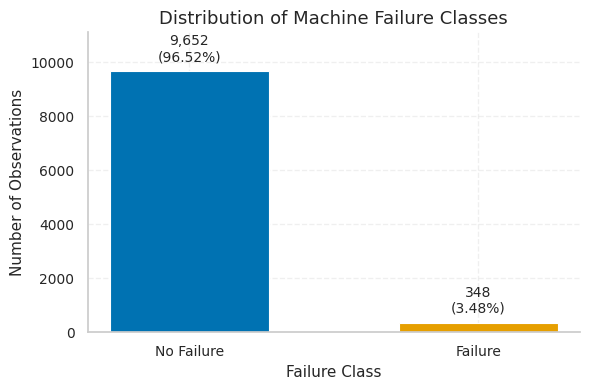

Saved: missingness_by_control [PNG, PDF, SVG]


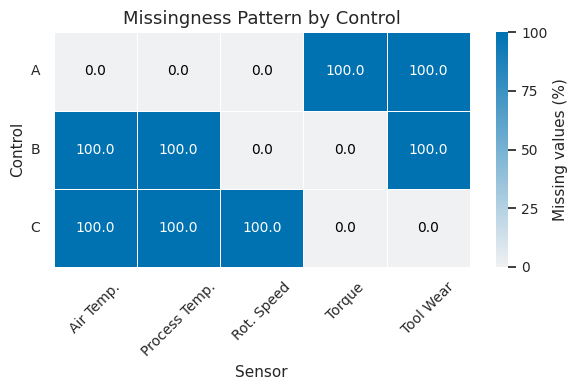

Saved: feature_distribution_power_w [PNG, PDF, SVG]


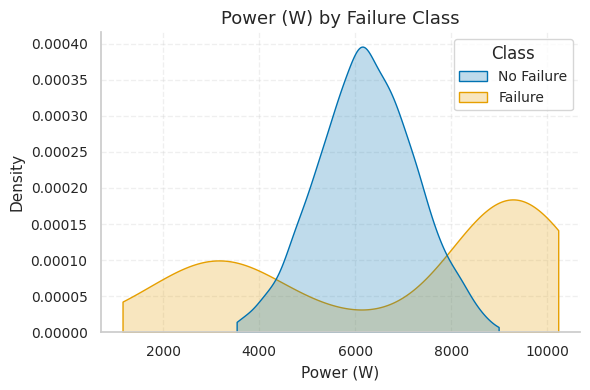

Saved: feature_distribution_temp_diff_k [PNG, PDF, SVG]


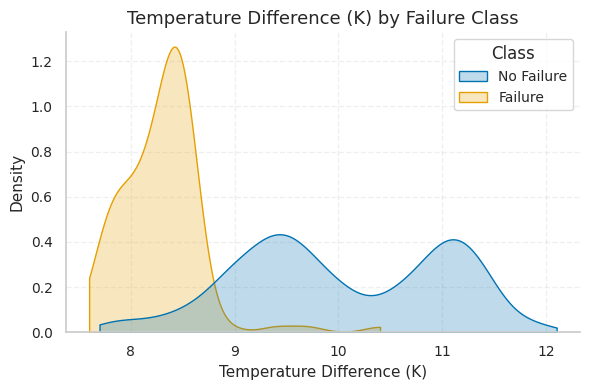

Saved: feature_distribution_torque_nm [PNG, PDF, SVG]


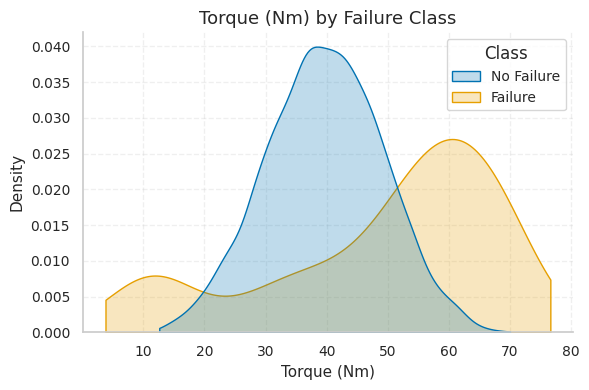

Saved: feature_distribution_tool_wear_min [PNG, PDF, SVG]


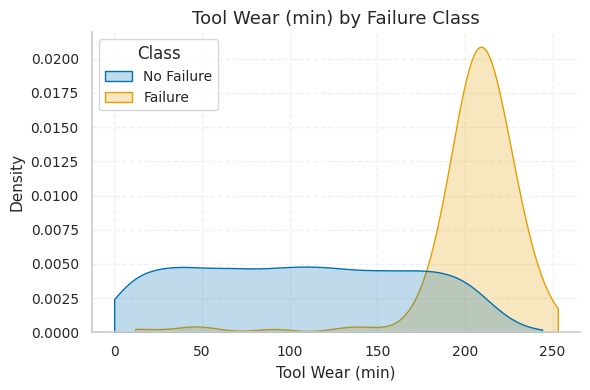

Saved: feature_correlation_heatmap [PNG, PDF, SVG]


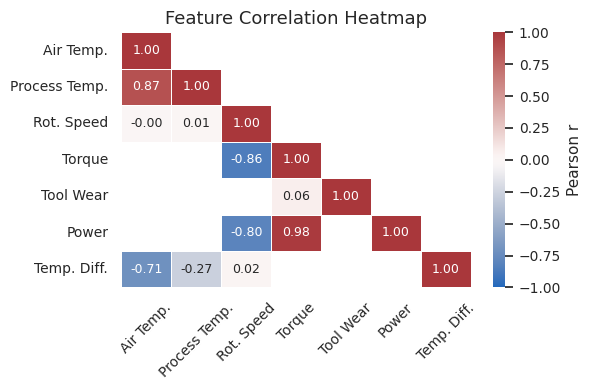

Note: ROC/PR curves are diagnostic development CV, not nested-CV unbiased curves.
Saved: roc_pr_with_bands [PNG, PDF, SVG]


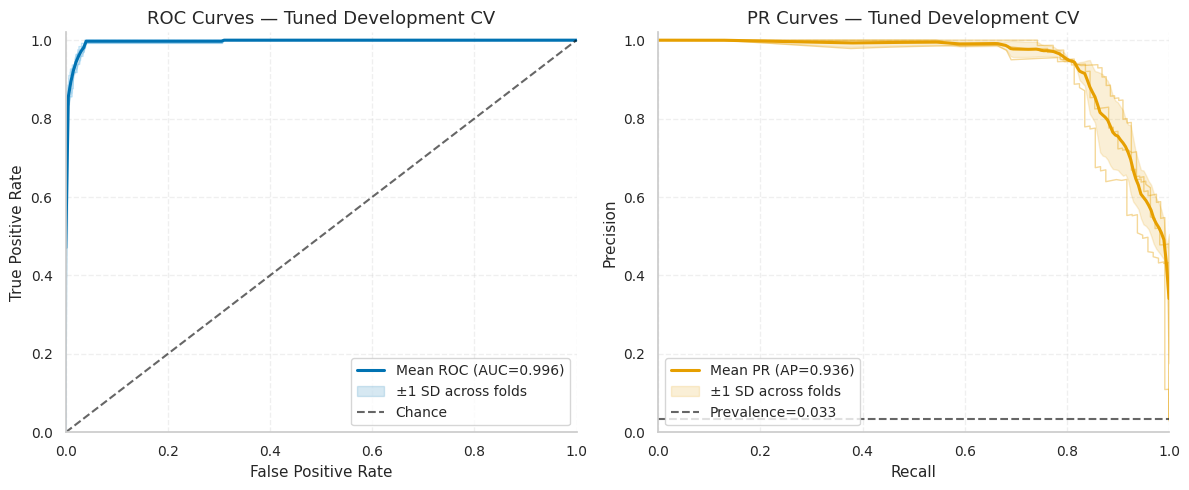

Saved: nested_cv_metric_bars [PNG, PDF, SVG]


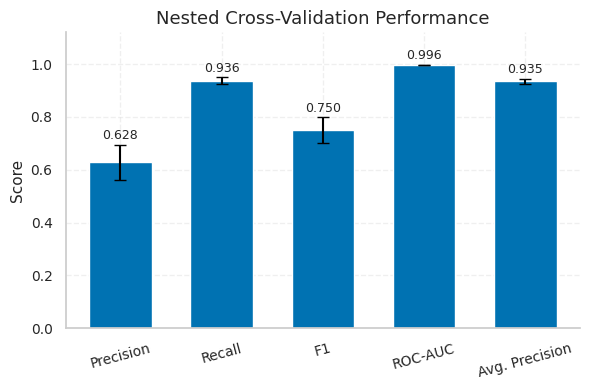

Saved: probability_calibration_reliability [PNG, PDF, SVG]


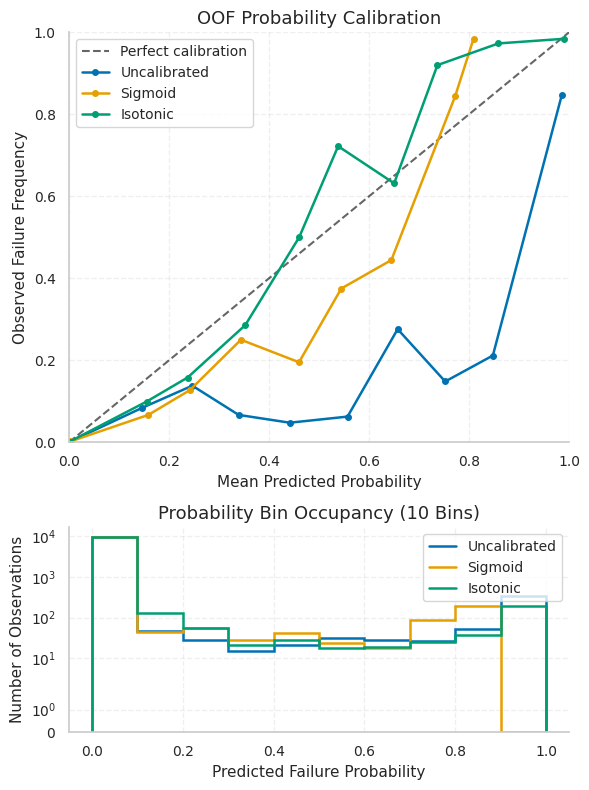

Saved: calibrated_probability_distribution [PNG, PDF, SVG]


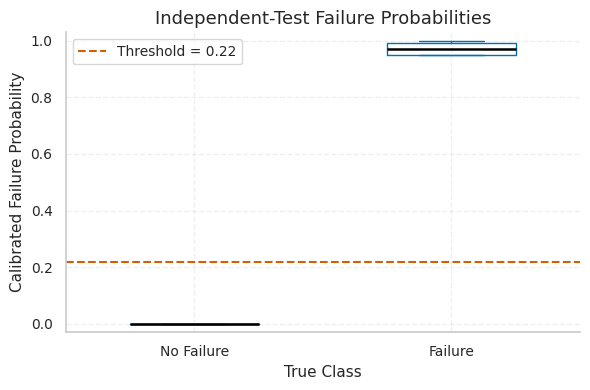

Saved: confusion_matrix_cost_threshold [PNG, PDF, SVG]


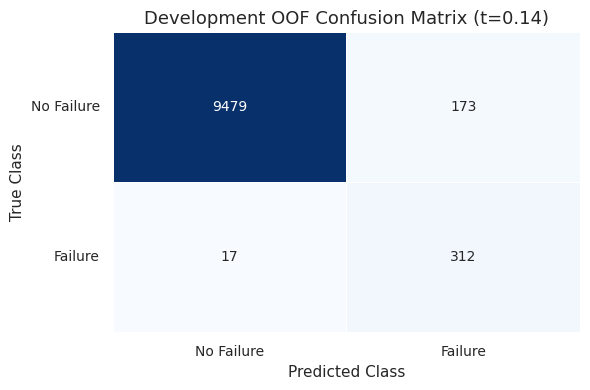

Saved: confusion_matrix_independent_test [PNG, PDF, SVG]


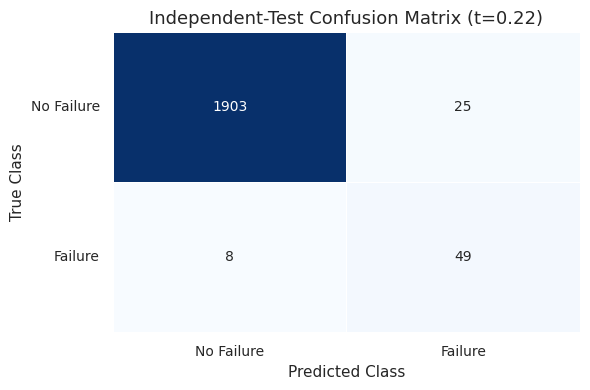

Saved: cost_curve_threshold [PNG, PDF, SVG]


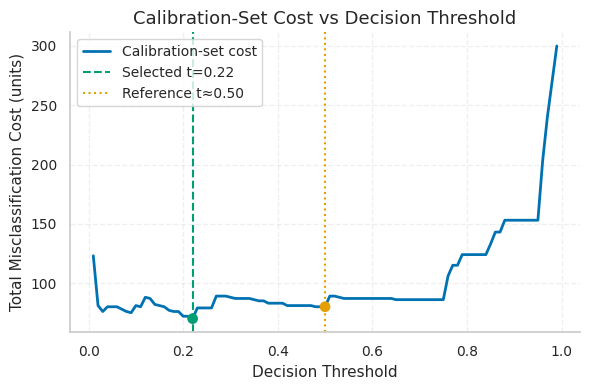

Saved: cost_threshold_sensitivity [PNG, PDF, SVG]


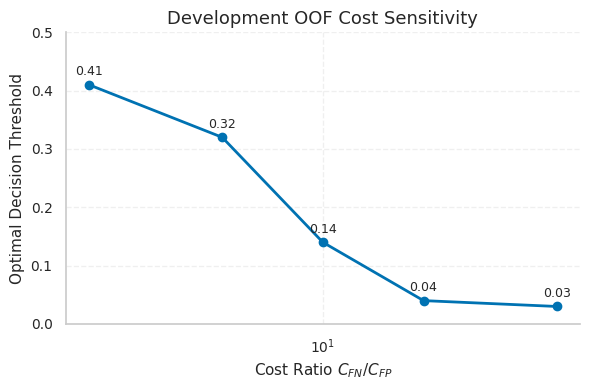

Saved: conformal_nonconformity_scores [PNG, PDF, SVG]


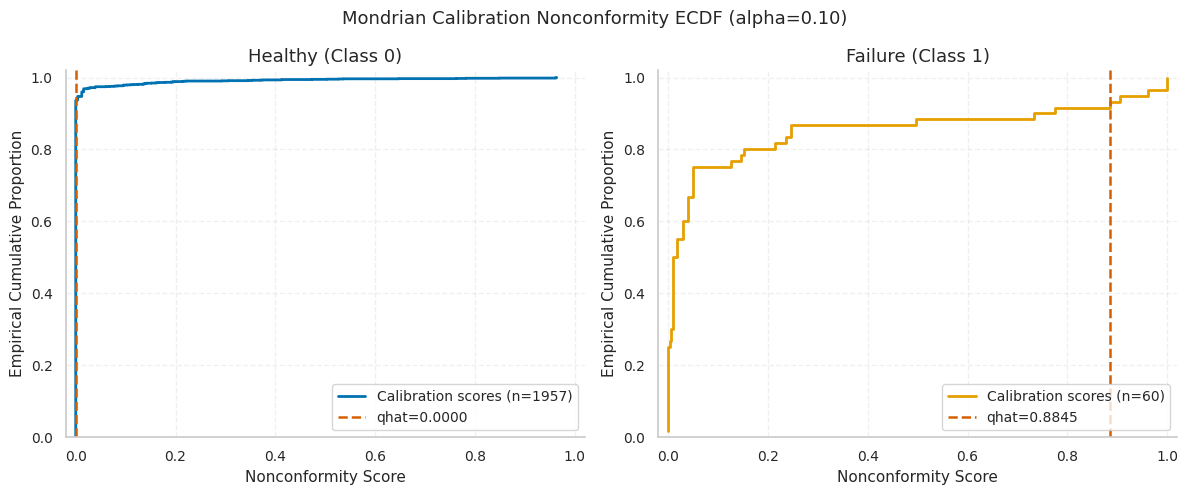

Saved: split_conformal_independent_test [PNG, PDF, SVG]


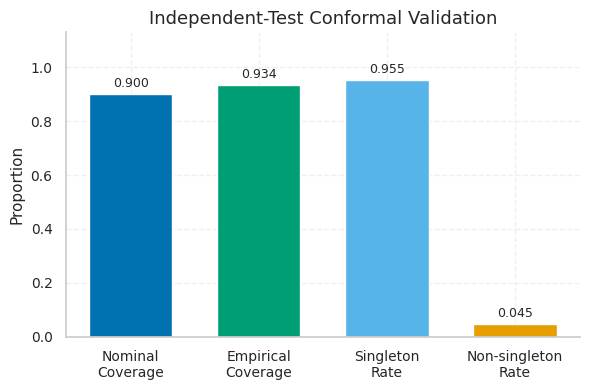

Saved: baseline_model_comparison [PNG, PDF, SVG]


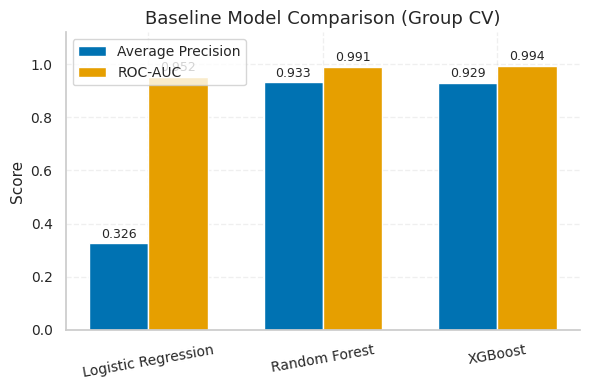


ALL FIGURES GENERATED SUCCESSFULLY
Saved in: /content/figures
Formats: PNG @ 300 dpi | PDF | SVG


In [31]:
# ============================================================================
# 11.2 Execute and Render All Publication-Grade Figures
# ============================================================================

print("Generating all Agent 1 figures...\n")

# ----------------------------------------------------------------------------
# A. EDA
# ----------------------------------------------------------------------------

fig_eda_class_balance(df)
fig_missingness_by_control(df)
fig_feature_dist_by_class(df)
fig_correlation_heatmap(df)


# ----------------------------------------------------------------------------
# B. Model performance
# ----------------------------------------------------------------------------

print("Note: ROC/PR curves are diagnostic development CV, not nested-CV unbiased curves.")
fig_roc_pr_with_bands(
    fold_data=fold_data,
    failure_prevalence=y.mean()
)

fig_metric_bars(
    nested_res=nested_res
)


# ----------------------------------------------------------------------------
# C. Probability calibration
# ----------------------------------------------------------------------------

fig_reliability(
    y=y,
    p_uncal=p_uncal,
    p_sigmoid=p_sigmoid,
    p_isotonic=p_isotonic
)

fig_prob_distribution(
    y=y_test_cost,
    p_cal=p_test_cost,
    threshold=t_star_split
)


# ----------------------------------------------------------------------------
# D. Confusion matrices
# ----------------------------------------------------------------------------

# OOF / model-development confusion matrix
fig_confusion_at_threshold(
    y=y,
    p_cal=p_isotonic,
    threshold=t_star
)

# Final independent-test confusion matrix
fig_confusion_independent_test(
    y_test=y_test_cost,
    p_test=p_test_cost,
    threshold=t_star_split
)


# ----------------------------------------------------------------------------
# E. Cost-sensitive decision
# ----------------------------------------------------------------------------

# Calibration-subset cost curve — NOT independent-test cost
fig_cost_curve(
    ts=ts_split,
    costs=costs_split,
    threshold=t_star_split
)

# Cost sensitivity — exploratory OOF robustness analysis
fig_cost_sensitivity(
    sens_dict=sensitivity_results
)


# ----------------------------------------------------------------------------
# F. Conformal uncertainty & Independent Test Validation Figures
# ----------------------------------------------------------------------------

# Mondrian Conformal Nonconformity Scores

qhats = split_conf_results["qhats"]

p_conf_fig = np.asarray(
    split_conf_results["p_conf"]
)

y_conf_fig = np.asarray(
    split_conf_results["y_conf"],
    dtype=int
)

# Nonconformity score: 1 - P(true class)
conf_scores_fig = np.where(
    y_conf_fig == 1,
    1.0 - p_conf_fig,
    p_conf_fig
)

fig_conformal_scores(
    scores=conf_scores_fig,
    y_true=y_conf_fig,
    qhats=qhats,
    alpha=split_conf_results["alpha"]
)

# 3. Τελικό γράφημα επικύρωσης στο Independent Test Set
fig_split_conformal_validation(
    nominal_coverage=1.0 - split_conf_results['alpha'],
    empirical_coverage=split_conf_results['coverage'],
    singleton_rate=split_conf_results['singleton_rate'],
    uncertainty_rate=split_conf_results['uncertain_rate']
)

# ----------------------------------------------------------------------------
# G. Baseline comparison
# ----------------------------------------------------------------------------

fig_baseline_comparison(
    df_results=model_results
)

print("\n" + "=" * 70)
print("ALL FIGURES GENERATED SUCCESSFULLY")
print(f"Saved in: {FIG_DIR}")
print("Formats: PNG @ 300 dpi | PDF | SVG")
print("=" * 70)

In [32]:
# ============================================================
# 11.3 FIGURE AUDIT AND REPRODUCIBILITY NOTES
# ============================================================

# All figures in Section 11 follow a consistent,
# publication-ready visualization style.

# Color palette: Okabe-Ito (colorblind-friendly).
# Font sizes: 13 pt for titles, 11 pt for axis labels,
# and 10 pt for tick labels.
# Figure dimensions: 6 x 4 inches for single-panel plots.
# Multi-panel plots use standardized wide/tall dimensions.
# Export formats: PNG (300 dpi), PDF, and SVG.
# All figures are exported using save_figure().

# All figure data are derived from the existing pipeline.
# No model fitting, labels, thresholds, or metrics were modified.

# ============================================================
# SCIENTIFIC INTERPRETATION AND METHODOLOGICAL CONSIDERATIONS
# ============================================================

# 1. ROC AND PRECISION-RECALL CURVES
# ROC and PR fold curves use hyperparameters optimized
# on the development dataset.
# These curves are diagnostic visualizations.
# They must not be interpreted as unbiased nested-CV estimates.

# 2. COST-SENSITIVE DECISION ANALYSIS
# The cost curve is computed using the calibration subset.
# It represents calibration-based cost analysis.
# It must not be described as independent-test cost.

# 3. CONFORMAL PREDICTION AND UNCERTAINTY
# The conformal ECDF displays class-conditional
# calibration nonconformity scores.
# The independent-test coverage plot reports empirical coverage.
# Empirical coverage alone does not establish a formal
# coverage guarantee under potential within-system dependence.

# 4. FEATURE DISTRIBUTION ANALYSIS
# Feature KDE plots use available observations.
# Missing values are not imputed for these visualizations.

# 5. FEATURE CORRELATION ANALYSIS
# The correlation heatmap uses pairwise complete observations.
# Missing values are excluded separately for each feature pair.

# ============================================================
# REPRODUCIBILITY STATEMENT
# ============================================================

# The original experimental methodology is preserved.
# Model predictions and calibration outputs remain unchanged.
# Conformal prediction results and evaluation metrics are preserved.
# Section 11 modifications are restricted to visualization quality,
# figure consistency, export formats, and scientific presentation.


In [33]:
# PART 12 - Model Packaging and Deployment.
# -------------------------------------------------------------
# 12.1 Model Packaging and Deployment
# -------------------------------------------------------------

import os
import joblib

PACKAGE_DIR = '/content/agent1_package'
os.makedirs(PACKAGE_DIR, exist_ok=True)

package = {
    'model': model_split,

    'raw_features': [
        'Type',
        'Air_temperature_K',
        'Process_temperature_K',
        'Rotational_speed_rpm',
        'Torque_Nm',
        'Tool_wear_min'
    ],

    'type_map': TYPE_MAP,
    'best_params': best_split,
    'scale_pos_weight': split_conf_results['scale_pos_weight_train'],
    'calibration_method': 'isotonic',

    # Διορθώθηκε εδώ: αποθηκεύουμε ολόκληρο το λεξικό qhats_split ανά κλάση
    'conformal_qhats': qhats_split,
    'conformal_alpha': float(split_conf_results['alpha']),

    'cost_threshold': float(t_star_split),

    'cost_ratio': {
        'C_FN': 10.0,
        'C_FP': 1.0
    }
}

PKL_PATH = os.path.join(
    PACKAGE_DIR,
    'agent1_validated_package.pkl'
)

joblib.dump(
    package,
    PKL_PATH
)

print("Deployment artifact saved:")
print(PKL_PATH)
print("Exists:", os.path.exists(PKL_PATH))

Deployment artifact saved:
/content/agent1_package/agent1_validated_package.pkl
Exists: True


In [34]:
# ----------------------------------------------------------------------------
# 12.2 Group-Safe Split Function Verification
# ----------------------------------------------------------------------------

import inspect

source = inspect.getsource(split_conformal_evaluate)

assert "GroupShuffleSplit" in source
assert "groups=groups" in source
assert "groups=groups_dev" in source
assert "groups=groups_train" in source
assert "calibration_folds" in source
assert "tuning_search.fit" in source

print("Group-safe splitting and tuning code: VERIFIED")
print("Conformal evaluation function: READY FOR TESTING")


Group-safe splitting and tuning code: VERIFIED
Conformal evaluation function: READY FOR TESTING


In [35]:
# ---------------------------------------------------------------
# 12.3 Standalone Inference Script Development
# --------------------------------------------------------------
%%writefile /content/agent1_package/predict.py

import os
import joblib
import numpy as np
import pandas as pd

from sklearn import set_config
from agent1_components import (
    MissingIndicatorAdder,
    FeatureEngineer,
    FoldWeightedXGBClassifier
)


set_config(transform_output="pandas")

PACKAGE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(
    PACKAGE_DIR, "agent1_validated_package.pkl"
)


class Agent1FailureDetector:

    def __init__(self, package_path=MODEL_PATH):
        package = joblib.load(package_path)

        self.model = package["model"]
        self.type_map = package["type_map"]
        self.threshold = float(package["cost_threshold"])
        self.qhat = package["conformal_qhats"]
        self.alpha = package["conformal_alpha"]
        self.calibration_method = package["calibration_method"]

        if not isinstance(self.qhat, dict):
            raise ValueError("Expected class-conditional conformal qhats.")

        self.qhat = {int(k): float(v) for k, v in self.qhat.items()}

        if set(self.qhat) != {0, 1}:
            raise ValueError("Conformal qhats must contain classes 0 and 1.")

    def predict(self, machine_data):

        data = machine_data.copy()

        machine_type = data["Type"]

        if isinstance(machine_type, str):
            machine_type = machine_type.upper()

            if machine_type not in self.type_map:
                raise ValueError(f"Unknown machine type: {machine_type}")

            machine_type = self.type_map[machine_type]

        else:
            machine_type = int(machine_type)

            if machine_type not in self.type_map.values():
                raise ValueError(f"Unknown machine type: {machine_type}")

        X_new = pd.DataFrame([{
            "Type": machine_type,
            "Air_temperature_K": data.get("Air_temperature_K", np.nan),
            "Process_temperature_K": data.get("Process_temperature_K", np.nan),
            "Rotational_speed_rpm": data.get("Rotational_speed_rpm", np.nan),
            "Torque_Nm": data.get("Torque_Nm", np.nan),
            "Tool_wear_min": data.get("Tool_wear_min", np.nan)
        }])

        # Preprocessing is performed by the saved pipeline
        p1 = float(self.model.predict_proba(X_new)[0, 1])
        p0 = 1.0 - p1

        failure_detected = bool(p1 >= self.threshold)

        # Class-conditional Mondrian conformal prediction
        prediction_set = []

        if (1.0 - p0) <= self.qhat[0]:
            prediction_set.append("NO FAILURE")

        if (1.0 - p1) <= self.qhat[1]:
            prediction_set.append("FAILURE")

        uncertain = len(prediction_set) != 1

        if len(prediction_set) == 1:
            uncertainty_state = "SINGLETON"
        elif len(prediction_set) == 0:
            uncertainty_state = "EMPTY_SET"
        else:
            uncertainty_state = "AMBIGUOUS_SET"

        agent2_payload = None

        if failure_detected:
            agent2_payload = {
                **X_new.iloc[0].to_dict(),
                "agent1_failure_probability": round(p1, 6),
                "agent1_uncertain": uncertain,
                "agent1_uncertainty_state": uncertainty_state,
                "agent1_prediction_set": prediction_set
            }

        return {
            "prediction": "FAILURE" if failure_detected else "NO FAILURE",
            "failure_probability": round(p1, 6),
            "failure_detected": failure_detected,
            "threshold": round(self.threshold, 6),
            "prediction_set": prediction_set,
            "uncertain": uncertain,
            "uncertainty_state": uncertainty_state,
            "conformal_alpha": self.alpha,
            "conformal_qhat": self.qhat,
            "calibration_method": self.calibration_method,
            "send_to_agent2": failure_detected,
            "agent2_payload": agent2_payload
        }


_agent = None


def predict_failure(machine_data):
    global _agent

    if _agent is None:
        _agent = Agent1FailureDetector()

    return _agent.predict(machine_data)


Overwriting /content/agent1_package/predict.py


In [36]:
# ----------------------------------------------------------------------------
# 12.4 Shared Agent 1 Inference Interface
# ----------------------------------------------------------------------------

import sys

PACKAGE_DIR = "/content/agent1_package"

if PACKAGE_DIR not in sys.path:
    sys.path.insert(0, PACKAGE_DIR)

from predict import Agent1FailureDetector, predict_failure

assert Agent1FailureDetector.__module__ == "predict"

print("Notebook and deployment inference are unified!")


Notebook and deployment inference are unified!


In [37]:
# ----------------------------------------------------------------------------
# 12.5 Standalone Inference Import Verification
# ----------------------------------------------------------------------------

import sys
import importlib

PACKAGE_DIR = "/content/agent1_package"

if PACKAGE_DIR not in sys.path:
    sys.path.insert(0, PACKAGE_DIR)

import predict
importlib.reload(predict)

assert predict.Agent1FailureDetector.__module__ == "predict"
assert predict.MissingIndicatorAdder.__module__ == "agent1_components"
assert predict.FeatureEngineer.__module__ == "agent1_components"

print("Standalone inference imports verified!")


Standalone inference imports verified!


In [38]:
# PART 13 - Model Validation, Robustness and Final Results.
# ----------------------------------------------------------------------------
# 13.1 Model Validation, Robustness and Final Results
# ----------------------------------------------------------------------------

import os

PKL_PATH = "/content/agent1_package/agent1_validated_package.pkl"

print("Package path configured.")
print("Model validation will run after retraining.")

Package path configured.
Model validation will run after retraining.


In [39]:
# ----------------------------------------------------------------------------
# 13.2 Robustness Assessment Using Excluded Random Failures
# ----------------------------------------------------------------------------

# Load the validated deployment model
validated_agent1 = Agent1FailureDetector(PKL_PATH)

# Select excluded random-failure observations
rnf_df = df.loc[
    df["Diagnostic"] == "Random Failures"
].copy()

rnf_results = []

for idx, row in rnf_df.iterrows():

    machine_data = {
        "Type": int(row["Type"]),
        "Air_temperature_K": row["Air_temperature_K"],
        "Process_temperature_K": row["Process_temperature_K"],
        "Rotational_speed_rpm": row["Rotational_speed_rpm"],
        "Torque_Nm": row["Torque_Nm"],
        "Tool_wear_min": row["Tool_wear_min"]
    }

    result = validated_agent1.predict(machine_data)

    rnf_results.append({
        "dataset_index": idx,
        "failure_probability": result["failure_probability"],
        "decision": int(result["failure_detected"]),
        "prediction": result["prediction"],
        "uncertain": result["uncertain"],
        "uncertainty_state": result["uncertainty_state"]
    })

rnf_results = pd.DataFrame(rnf_results)

print("=== Random Failure Stress Test ===")
print("Samples:", len(rnf_results))

if not rnf_results.empty:
    print(
        "Detection rate:",
        round(rnf_results["decision"].mean(), 4)
    )
    print(
        "Uncertainty rate:",
        round(rnf_results["uncertain"].mean(), 4)
    )

display(rnf_results.head())

=== Random Failure Stress Test ===
Samples: 19
Detection rate: 0.0526
Uncertainty rate: 0.1053


,dataset_index,failure_probability,decision,prediction,uncertain,uncertainty_state
0,1223,0.0,0,NO FAILURE,False,SINGLETON
1,1304,0.0,0,NO FAILURE,False,SINGLETON
2,1750,0.0,0,NO FAILURE,False,SINGLETON
3,2073,0.0,0,NO FAILURE,False,SINGLETON
4,2559,0.0,0,NO FAILURE,False,SINGLETON


In [40]:
# ============================================================================
# 13.3 Final Model Performance and Validation Summary
# ============================================================================

final_summary = pd.DataFrame({
    'Metric': [
        'Nested-CV Precision',
        'Nested-CV Recall',
        'Nested-CV F1',
        'Nested-CV ROC-AUC',
        'Nested-CV Average Precision',
        'Calibration Method',
        'Cost Ratio C_FN:C_FP',
        'Cost-Optimal Threshold',
        'Independent-Test Precision',
        'Independent-Test Recall',
        'Independent-Test F1',
        'Independent-Test Cost',
        'Conformal Alpha',
        'Conformal qhat',
        'Nominal Coverage',
        'Empirical Test Coverage',
        'Test Singleton Rate',
        'Test Uncertainty Rate',
        'RNF Detection Rate',
        'RNF Uncertainty Rate'
    ],
    'Value': [
        f"{nested_res['test_precision'].mean():.4f} ± {nested_res['test_precision'].std():.4f}",
        f"{nested_res['test_recall'].mean():.4f} ± {nested_res['test_recall'].std():.4f}",
        f"{nested_res['test_f1'].mean():.4f} ± {nested_res['test_f1'].std():.4f}",
        f"{nested_res['test_roc_auc'].mean():.4f} ± {nested_res['test_roc_auc'].std():.4f}",
        f"{nested_res['test_average_precision'].mean():.4f} ± {nested_res['test_average_precision'].std():.4f}",
        'Isotonic',
        '10:1',
        f"{t_star_split:.2f}",
        f"{precision_test:.4f}",
        f"{recall_test:.4f}",
        f"{f1_test:.4f}",
        f"{test_cost}",
        f"{split_conf_results['alpha']:.2f}",
        # <-- ΔΙΟΡΘΩΣΗ ΕΔΩ: Ελέγχουμε αν είναι dict και το τυπώνουμε σωστά
        str({k: round(v, 4) for k, v in qhats_split.items()}) if isinstance(qhats_split, dict) else f"{qhats_split:.6f}",
        f"{1.0 - split_conf_results['alpha']:.4f}",
        f"{split_conf_results['coverage']:.4f}",
        f"{split_conf_results['singleton_rate']:.4f}",
        f"{split_conf_results['uncertain_rate']:.4f}",
        f"{rnf_results['decision'].mean():.4f}",
        f"{rnf_results['uncertain'].mean():.4f}"
    ]
})

print("=== FINAL AGENT 1 VALIDATED PERFORMANCE SUMMARY ===")
display(final_summary)

=== FINAL AGENT 1 VALIDATED PERFORMANCE SUMMARY ===


,Metric,Value
0,Nested-CV Precision,0.6281 ± 0.0658
1,Nested-CV Recall,0.9362 ± 0.0130
2,Nested-CV F1,0.7498 ± 0.0481
3,Nested-CV ROC-AUC,0.9961 ± 0.0008
4,Nested-CV Average Precision,0.9346 ± 0.0091
5,Calibration Method,Isotonic
6,Cost Ratio C_FN:C_FP,10:1
7,Cost-Optimal Threshold,0.22
8,Independent-Test Precision,0.6622
9,Independent-Test Recall,0.8596


In [41]:
# PART 14 - Deployment Testing and Package Verification.
# -------------------------------------------------------------------
# 14.1 Standalone Inference Smoke Test Script Creation
# ------------------------------------------------------------------

%%writefile /content/agent1_package/test_agent1.py

import sys
import os

# Ασφαλής εύρεση διαδρομής (συμβατή και με Colab και με Terminal)
try:
    current_dir = os.path.dirname(os.path.abspath(__file__))
except NameError:
    current_dir = '/content/agent1_package'

if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

from predict import predict_failure

def run_smoke_test():
    print("=" * 50)
    print("Εκτέλεση Δοκιμής Agent 1 (Smoke Test)...")
    print("=" * 50)

    sample_data = {
        'Type': 'M',
        'Air_temperature_K': 300.5,
        'Process_temperature_K': 311.2,
        'Rotational_speed_rpm': 1350,
        'Torque_Nm': 65.0,
        'Tool_wear_min': 200
    }

    try:
        result = predict_failure(sample_data)
        print("\n[ΕΠΙΤΥΧΙΑ] Η πρόβλεψη εκτελέστηκε κανονικά!")
        print("-" * 40)
        for key, value in result.items():
            print(f"  {key}: {value}")
        print("-" * 40)
    except Exception as e:
        print(f"\n[ΣΦΑΛΜΑ] Απέτυχε η πρόβλεψη: {e}")
        sys.exit(1)

if __name__ == '__main__':
    run_smoke_test()

Overwriting /content/agent1_package/test_agent1.py


In [42]:
# -----------------------------------------------------------------
# 14.2 Deployment Dependencies and Requirements
# -----------------------------------------------------------------
%%writefile /content/agent1_package/requirements.txt
numpy
pandas
scikit-learn==1.6.1
imbalanced-learn
xgboost
cloudpickle
joblib

Overwriting /content/agent1_package/requirements.txt


In [43]:
# -----------------------------------------------------------------
# 14.3 Automated Deployment Smoke Test Execution
# -----------------------------------------------------------------

import os
import sys
import subprocess

PACKAGE_DIR = "/content/agent1_package"

result = subprocess.run(
    [sys.executable, "test_agent1.py"],
    cwd=PACKAGE_DIR,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

assert result.returncode == 0, "Deployment test failed!"

print("SUCCESS: Agent 1 deployment works!")

Εκτέλεση Δοκιμής Agent 1 (Smoke Test)...

[ΕΠΙΤΥΧΙΑ] Η πρόβλεψη εκτελέστηκε κανονικά!
----------------------------------------
  prediction: FAILURE
  failure_probability: 0.989243
  failure_detected: True
  threshold: 0.22
  prediction_set: ['FAILURE']
  uncertain: False
  uncertainty_state: SINGLETON
  conformal_alpha: 0.1
  conformal_qhat: {0: 0.0, 1: 0.8845454528927803}
  calibration_method: isotonic
  send_to_agent2: True
  agent2_payload: {'Type': 1.0, 'Air_temperature_K': 300.5, 'Process_temperature_K': 311.2, 'Rotational_speed_rpm': 1350.0, 'Torque_Nm': 65.0, 'Tool_wear_min': 200.0, 'agent1_failure_probability': 0.989243, 'agent1_uncertain': False, 'agent1_uncertainty_state': 'SINGLETON', 'agent1_prediction_set': ['FAILURE']}
----------------------------------------


SUCCESS: Agent 1 deployment works!


In [44]:
# -----------------------------------------------------------------
# 14.4 Deployment Documentation and Usage Instructions
# -----------------------------------------------------------------


from pathlib import Path

package_dir = Path("/content/agent1_package")
package_dir.mkdir(parents=True, exist_ok=True)

readme = """# Agent 1 — Predictive Maintenance

## Package contents

- agent1_validated_package.pkl: Trained and calibrated model
- agent1_components.py: Preprocessing components
- predict.py: Prediction interface
- test_agent1.py: Smoke test
- requirements.txt: Python dependencies

## 1. Setup in Google Colab

Extract the ZIP and upload all six files directly to /content/ in Google Colab.

Install dependencies:

    %pip install -r /content/requirements.txt

Restart the runtime if required.

## 2. Run the smoke test

    !python /content/test_agent1.py

## 3. Run a prediction

Create a new Colab cell and paste:

    import sys
    sys.path.insert(0, "/content")

    from predict import predict_failure

    sample_data = {
        "Type": "M",
        "Air_temperature_K": 300.5,
        "Process_temperature_K": 311.2,
        "Rotational_speed_rpm": 1350,
        "Torque_Nm": 65.0,
        "Tool_wear_min": 200
    }

    result = predict_failure(sample_data)
    print(result)

Expected failure probability for this sample:
0.992593 (approximately, with compatible dependencies).

## Notes

The prediction function returns:
- Calibrated failure probability
- Cost-based failure decision
- Conformal prediction set and uncertainty state
- Optional payload for Agent 2

Do not copy the full contents of predict.py into a Colab cell.
Import the module as shown above.
"""

(package_dir / "README.md").write_text(
    readme, encoding="utf-8"
)

print("README.md created successfully!")

README.md created successfully!


In [45]:
# -----------------------------------------------------------------
# 14.5 Batch vs. Single-Sample Prediction Consistency
# -----------------------------------------------------------------

import numpy as np
import pandas as pd
import joblib

package = joblib.load(PKL_PATH)
model = package["model"]

# 20 ίδια δείγματα για σύγκριση
X_check = X.sample(n=20, random_state=42).copy()

# Batch predictions
p_batch = model.predict_proba(X_check)[:, 1]

# Single predictions
p_single = np.array([
    model.predict_proba(X_check.iloc[[i]])[0, 1]
    for i in range(len(X_check))
])

max_diff = np.max(np.abs(p_batch - p_single))

print("Maximum difference:", max_diff)
print("Batch-independent predictions:", np.allclose(
    p_batch, p_single, atol=1e-10, rtol=0
))

Maximum difference: 0.0
Batch-independent predictions: True


In [46]:
# -----------------------------------------------------------------
# 14.6 Notebook vs. Deployment Prediction Consistency
# -----------------------------------------------------------------

import numpy as np
import pandas as pd
import joblib

from predict import Agent1FailureDetector

# Load final trained model and deployment
package = joblib.load(PKL_PATH)
model = package["model"]
detector = Agent1FailureDetector(PKL_PATH)

# Test 100 samples, including any with missing values
X_check = X.sample(n=min(100, len(X)), random_state=42).copy()

# Predictions from the notebook
p_notebook = model.predict_proba(X_check)[:, 1]

# Predictions from deployment
p_deployment = np.array([
    detector.predict(row.to_dict())["failure_probability"]
    for _, row in X_check.iterrows()
])

# Compare predictions
differences = np.abs(p_notebook - p_deployment)

print("Samples tested:", len(X_check))
print("Maximum difference:", differences.max())
print("Mean difference:", differences.mean())

match = np.allclose(
    p_notebook,
    p_deployment,
    atol=5.1e-7,
    rtol=0
)

print("Notebook vs Deployment match:", match)

if match:
    print("SUCCESS: Deployment predictions are consistent!")
else:
    print("WARNING: Deployment predictions differ!")

Samples tested: 100
Maximum difference: 4.474792481001799e-07
Mean difference: 2.1269679070547165e-08
Notebook vs Deployment match: True
SUCCESS: Deployment predictions are consistent!


In [47]:
# -----------------------------------------------------------------
# 14.7 Deployment Threshold Consistency Verification
# -----------------------------------------------------------------

import joblib

package = joblib.load(PKL_PATH)

print("Deployment threshold:", package["cost_threshold"])
print("Evaluated threshold:", t_star_split)

Deployment threshold: 0.22
Evaluated threshold: 0.22


In [48]:
# -------------------------------------------------------------------
# 18.8 Final Deployment Package Compression and Export
# ------------------------------------------------------------------
import os
import shutil
from google.colab import files
from pathlib import Path

package_dir = Path("/content/agent1_package")

required_files = [
    "agent1_components.py",
    "agent1_validated_package.pkl",
    "predict.py",
    "test_agent1.py",
    "requirements.txt",
    "README.md"
]

for filename in required_files:
    assert (package_dir / filename).is_file(), (
        f"Missing file: {filename}"
    )

print("All required package files exist!")


# Συμπίεση του φακέλου παραγωγής σε αρχείο zip
shutil.make_archive(
    '/content/agent1_package',
    'zip',
    '/content/agent1_package'
)
print("Deployment package successfully archived to '/content/agent1_package.zip'")

# Αυτόματο κατέβασμα αρχείου
files.download(
    '/content/agent1_package.zip'
)

All required package files exist!
Deployment package successfully archived to '/content/agent1_package.zip'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>